# CKD Pipeline Runner — Revision 1 (MLWA-D-26-01812) — Google Colab

## 1. Environment (pinned to the configuration that reproduced the paper)

In [ ]:
# Versions of the Colab session that reproduced every published value
# (2026-11-13: Linux, 2 cores, XGBoost 3.4.1 Linux wheel built with GCC 10.3.1).
# First run: installs any mismatched package; if a package that Colab had
# already loaded is changed, the runtime restarts automatically.
# After a restart: Runtime -> Run all.
import importlib.metadata as md
import os
import subprocess
import sys

PINNED = {
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "xgboost": "3.4.1",
    "lightgbm": "4.7.0",
    "imbalanced-learn": "0.14.2",
    "statsmodels": "0.15.0",
    "joblib": "1.6.0",
    "threadpoolctl": "3.7.0",
}
IMPORT_NAMES = {"scikit-learn": "sklearn", "imbalanced-learn": "imblearn"}

def installed(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None

mismatch = {p: installed(p) for p, v in PINNED.items() if installed(p) != v}

if mismatch:
    print("Installing pinned versions for:", mismatch)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           *[f"{p}=={PINNED[p]}" for p in mismatch]])
    already_loaded = [p for p in mismatch
                      if IMPORT_NAMES.get(p, p.replace("-", "_")) in sys.modules]
    if already_loaded:
        print("Restarting runtime (already-loaded packages changed:", already_loaded, ")")
        print("When it reconnects: Runtime -> Run all.")
        os.kill(os.getpid(), 9)

for p, v in PINNED.items():
    got = installed(p)
    print(f"{p:<18} {got:<10} {'OK' if got == v else 'MISMATCH'}")
if any(installed(p) != v for p, v in PINNED.items()):
    raise RuntimeError("Pinned versions not active. Restart the runtime and Run all again.")

import platform
import xgboost
b = xgboost.build_info()
print("\nPython      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("CPU cores   :", os.cpu_count())
print("XGBoost build: GCC", ".".join(map(str, b.get("GCC_VERSION", []))),
      "(reproduction used GCC 10.3.1)")

Installing pinned versions for: {'lightgbm': '4.6.0'}
numpy              2.4.6      OK
pandas             2.2.3      OK
scipy              1.16.3     OK
scikit-learn       1.6.1      OK
xgboost            3.4.1      OK
lightgbm           4.7.0      OK
imbalanced-learn   0.14.2     OK
statsmodels        0.15.0     OK
joblib             1.6.0      OK
threadpoolctl      3.7.0      OK

Python      : 3.13.16
Platform    : Linux-6.6.159+-x86_64-with-glibc2.39
CPU cores   : 8
XGBoost build: GCC 10.3.1 (reproduction used GCC 10.3.1)


## 2. Google Drive, project folder, environment record

In [ ]:
import json
import shutil
import time
import datetime
import zipfile
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_FOLDER = Path("/content/drive/MyDrive/CKD-Paper-Final")
ZIP_PATH = DRIVE_FOLDER / "ckd-project.zip"

EXPECTED_MODULES = 42   # modules 00-41 (40 and 41 are the figure stages)

def module_count(folder):
    return len(list((folder / "modules").glob("[0-9][0-9]_*.py")))

def find_project(base):
    """Every folder (up to 3 levels deep) holding pipeline_runner.py + modules/."""
    hits = []
    for runner_file in base.glob("**/pipeline_runner.py"):
        folder = runner_file.parent
        depth = len(folder.relative_to(base).parts)
        if depth <= 3 and (folder / "modules").is_dir():
            hits.append((module_count(folder), folder))
    return hits

candidates = find_project(DRIVE_FOLDER)
complete = [f for n, f in candidates if n == EXPECTED_MODULES]

if not complete and ZIP_PATH.exists():
    print("No complete project found; extracting", ZIP_PATH.name)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DRIVE_FOLDER)
    candidates = find_project(DRIVE_FOLDER)
    complete = [f for n, f in candidates if n == EXPECTED_MODULES]

for n, f in sorted(candidates, key=lambda t: str(t[1])):
    print(f"found: {f.relative_to(DRIVE_FOLDER)}  ({n} modules){'  <- complete' if n == EXPECTED_MODULES else '  (old/incomplete, ignored)'}")

if not complete:
    raise FileNotFoundError(
        f"No folder with all {EXPECTED_MODULES} modules under {DRIVE_FOLDER}. "
        "Upload ckd-project.zip there and run this cell again."
    )

# Prefer the shallowest complete copy (e.g. ckd-project over ckd-project/ckd-project).
PROJECT_ROOT = min(complete, key=lambda f: len(f.relative_to(DRIVE_FOLDER).parts))
MODULE_NAMES = sorted(p.stem for p in (PROJECT_ROOT / "modules").glob("[0-9][0-9]_*.py"))
print("\nUsing PROJECT_ROOT:", PROJECT_ROOT)

# Keep earlier results: move them to a dated backup instead of deleting.
RESULTS = PROJECT_ROOT / "mlwa_results"
if RESULTS.exists() and any(RESULTS.iterdir()):
    backup = PROJECT_ROOT / f"mlwa_results_backup_{datetime.datetime.now():%Y%m%d_%H%M%S}"
    shutil.move(str(RESULTS), str(backup))
    print("Previous results moved to:", backup.name)

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Environment record for this run.
from threadpoolctl import threadpool_info
RESULTS.mkdir(parents=True, exist_ok=True)
env_record = {
    "captured_at": datetime.datetime.now().isoformat(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu_model": subprocess.run("lscpu | grep 'Model name'", shell=True,
                                capture_output=True, text=True).stdout.strip(),
    "cpu_count": os.cpu_count(),
    "versions": {p: installed(p) for p in PINNED},
    "xgboost_build": xgboost.build_info(),
    "thread_pools": [{k: t.get(k) for k in ("user_api", "internal_api", "num_threads", "version")}
                     for t in threadpool_info()],
}
(RESULTS / "run_environment.json").write_text(json.dumps(env_record, indent=2, default=str))
(RESULTS / "run_pip_freeze.txt").write_text(
    subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Modules     :", len(MODULE_NAMES))
print("Environment record saved: mlwa_results/run_environment.json, run_pip_freeze.txt")

Mounted at /content/drive
found: ckd-project  (42 modules)  <- complete

Using PROJECT_ROOT: /content/drive/MyDrive/CKD-Paper-Final/ckd-project
PROJECT_ROOT: /content/drive/MyDrive/CKD-Paper-Final/ckd-project
Modules     : 42
Environment record saved: mlwa_results/run_environment.json, run_pip_freeze.txt


## 3. Initialize pipeline

In [ ]:
import importlib
import pipeline_runner
importlib.reload(pipeline_runner)

from pipeline_runner import CKDPipelineRunner, banner, finish_block
from IPython.display import display

runner = CKDPipelineRunner(PROJECT_ROOT)

# True  = rebuild nhanes_ckd_risk_clean.csv from CDC/NCHS raw files
#         (corrected missing-creatinine/ACR exclusion; n = 5,063).
# False = use the shipped corrected CSV. Both give identical results.
RUN_DATA_PREPARATION = True

# Stop after Experiment 1 / Experiment 7 if published values do not reproduce.
REQUIRE_EXACT_REPRODUCTION = True

PIPELINE_T0 = time.time()

## 4. Original pipeline (modules 00–25)

In [ ]:
banner("SETUP: Paths, imports, and reproducibility settings")
t0 = time.time()

runner.setup()

finish_block(t0)


SETUP: Paths, imports, and reproducibility settings
Project root: /content/drive/MyDrive/CKD-Paper-Final/ckd-project
Dataset: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/nhanes_ckd_risk_clean.csv
Results directory: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results
Python: 3.13.16

Completed in 3.3 seconds.


3.3199496269226074

In [ ]:
banner("DATA PREPARATION: NHANES 2017–2018")
t0 = time.time()

if RUN_DATA_PREPARATION:
    runner.prepare_data()
else:
    print("Skipped. Using the shipped corrected development CSV (n = 5,063).")

finish_block(t0)


DATA PREPARATION: NHANES 2017–2018
CDC/NCHS NHANES source: https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles
Linked source dataset shape: (6401, 25)
Source participants: 6,401
Excluded age <18: 868
Adults after age filter: 5,533
Excluded for missing serum creatinine or urinary ACR: 470
Development adults retained: 5,063
Phenotype-positive cases: 939
Unweighted phenotype prevalence: 0.185463
Shape after removing outcome-source laboratory variables: (5063, 24)
Questionnaire recoding complete.
Final development cohort size: 5,063 (previously 5,533 before excluding participants with missing creatinine or ACR)
Phenotype-positive cases: 939 (previously 1,020)
Validation checks passed.
Final shape: (5063, 24)
CKD-compatible phenotype prevalence: 18.5463%
Per-variable missingness after outcome construction:
                 missing_n  missing_pct
ALQ130                1800    35.552044
INDFMPIR               652    12.877740
BPXSY1                 543    10.724867
BPXDI1            

9.77614426612854

In [ ]:
banner("DEVELOPMENT DATA: 2017–2018 cohort and survey design variables")
t0 = time.time()

runner.load_development_data()

finish_block(t0)


DEVELOPMENT DATA: 2017–2018 cohort and survey design variables
Development n: 5063
Unweighted CKD phenotype prevalence: 0.1855
Primary predictors: ['RIDAGEYR', 'RIAGENDR', 'DMDEDUC2', 'INDFMPIR', 'has_htn_dx', 'has_diabetes_dx', 'BMXBMI', 'BMXWAIST', 'smoked_100_cigs', 'ALQ130', 'mean_sbp', 'mean_dbp']
Survey-weighted CKD phenotype prevalence: 0.1378

Completed in 1.5 seconds.


1.546241283416748

In [ ]:
banner("PREPROCESSING: Imputation, encoding, and scaling")
t0 = time.time()

runner.build_preprocessor()

finish_block(t0)


PREPROCESSING: Imputation, encoding, and scaling

Completed in 0.9 seconds.


0.8627452850341797

In [ ]:
banner("MODEL SETUP: Candidate algorithms")
t0 = time.time()

runner.define_candidate_models()

finish_block(t0)


MODEL SETUP: Candidate algorithms

Completed in 0.9 seconds.


0.8736276626586914

In [ ]:
banner("EVALUATION METRICS")
t0 = time.time()

runner.define_metrics()

finish_block(t0)


EVALUATION METRICS

Completed in 0.8 seconds.


0.8225831985473633

In [ ]:
banner("EXPERIMENT 1: Nested five-fold cross-validation")
t0 = time.time()

runner.run_nested_cv()

model_comparison = runner.get("model_comparison")
if model_comparison is not None:
    display(model_comparison.round(4))

finish_block(t0)


EXPERIMENT 1: Nested five-fold cross-validation

=== Logistic Regression ===
fold 1: AUC=0.768, AP=0.474, Brier=0.125
fold 2: AUC=0.794, AP=0.469, Brier=0.187
fold 3: AUC=0.778, AP=0.467, Brier=0.124
fold 4: AUC=0.763, AP=0.495, Brier=0.124
fold 5: AUC=0.801, AP=0.495, Brier=0.122

=== Random Forest ===
fold 1: AUC=0.767, AP=0.477, Brier=0.157
fold 2: AUC=0.798, AP=0.455, Brier=0.123
fold 3: AUC=0.794, AP=0.483, Brier=0.123
fold 4: AUC=0.777, AP=0.493, Brier=0.125
fold 5: AUC=0.803, AP=0.511, Brier=0.121

=== HistGradientBoosting ===
fold 1: AUC=0.761, AP=0.486, Brier=0.124
fold 2: AUC=0.798, AP=0.472, Brier=0.124
fold 3: AUC=0.784, AP=0.465, Brier=0.123
fold 4: AUC=0.762, AP=0.451, Brier=0.127
fold 5: AUC=0.804, AP=0.513, Brier=0.121

=== XGBoost ===
fold 1: AUC=0.769, AP=0.498, Brier=0.171
fold 2: AUC=0.805, AP=0.482, Brier=0.122
fold 3: AUC=0.783, AP=0.476, Brier=0.123
fold 4: AUC=0.768, AP=0.465, Brier=0.125
fold 5: AUC=0.810, AP=0.534, Brier=0.118

=== LightGBM ===
fold 1: AUC=0.

,model,mean_roc_auc,sd_roc_auc,se_roc_auc,mean_pr_auc,sd_pr_auc,mean_brier,sd_brier,mean_log_loss,sd_log_loss
0,Random Forest,0.7879,0.0150,0.0067,0.4838,0.0206,0.1297,0.0153,0.4115,0.0404
1,XGBoost,0.7871,0.0200,0.0089,0.4908,0.0269,0.1320,0.0223,0.4173,0.0581
2,HistGradientBoosting,0.7819,0.0199,0.0089,0.4775,0.0237,0.1237,0.0023,0.3973,0.0080
3,LightGBM,0.7817,0.0201,0.0090,0.4779,0.0273,0.1572,0.0328,0.4823,0.0856
4,Logistic Regression,0.7808,0.0164,0.0073,0.4799,0.0140,0.1364,0.0283,0.4306,0.0713


Best mean outer-fold AUC: 0.7879
One-SE AUC cutoff: 0.7812

Competitive models:


,model,mean_roc_auc,se_roc_auc,mean_pr_auc,mean_brier,mean_log_loss
2,HistGradientBoosting,0.7819,0.0089,0.4775,0.1237,0.3973
0,Random Forest,0.7879,0.0067,0.4838,0.1297,0.4115
1,XGBoost,0.7871,0.0089,0.4908,0.1320,0.4173
3,LightGBM,0.7817,0.0090,0.4779,0.1572,0.4823


Selected model family: HistGradientBoosting


,model,mean_roc_auc,sd_roc_auc,se_roc_auc,mean_pr_auc,sd_pr_auc,mean_brier,sd_brier,mean_log_loss,sd_log_loss
0,Random Forest,0.7879,0.0150,0.0067,0.4838,0.0206,0.1297,0.0153,0.4115,0.0404
1,XGBoost,0.7871,0.0200,0.0089,0.4908,0.0269,0.1320,0.0223,0.4173,0.0581
2,HistGradientBoosting,0.7819,0.0199,0.0089,0.4775,0.0237,0.1237,0.0023,0.3973,0.0080
3,LightGBM,0.7817,0.0201,0.0090,0.4779,0.0273,0.1572,0.0328,0.4823,0.0856
4,Logistic Regression,0.7808,0.0164,0.0073,0.4799,0.0140,0.1364,0.0283,0.4306,0.0713



Completed in 546.9 seconds.


546.8639969825745

In [ ]:
banner("REPRODUCTION CHECK 1: nested CV (Table 2)")
published_cv = {
    "Random Forest":        (0.7879, 0.1297),
    "XGBoost":              (0.7871, 0.1320),
    "HistGradientBoosting": (0.7819, 0.1237),
    "LightGBM":             (0.7817, 0.1572),
    "Logistic Regression":  (0.7808, 0.1364),
}
mc = runner.get("model_comparison").set_index("model")
all_match = True
for model, (auc, brier) in published_cv.items():
    a = round(float(mc.loc[model, "mean_roc_auc"]), 4)
    b = round(float(mc.loc[model, "mean_brier"]), 4)
    ok = (a == auc) and (b == brier)
    all_match &= ok
    print(f"{model:<22} AUC {a:.4f} vs {auc:.4f} | Brier {b:.4f} vs {brier:.4f} | {'MATCH' if ok else 'DIFFERENT'}")
selected = runner.get("SELECTED_MODEL_NAME")
print("\nSelected model:", selected, "(published: HistGradientBoosting)")
all_match &= selected == "HistGradientBoosting"
print("\nREPRODUCTION CHECK 1:", "PASSED" if all_match else "FAILED")
if REQUIRE_EXACT_REPRODUCTION and not all_match:
    raise RuntimeError("Nested CV does not reproduce the published Table 2. Stopping before the long run.")


REPRODUCTION CHECK 1: nested CV (Table 2)
Random Forest          AUC 0.7879 vs 0.7879 | Brier 0.1297 vs 0.1297 | MATCH
XGBoost                AUC 0.7871 vs 0.7871 | Brier 0.1320 vs 0.1320 | MATCH
HistGradientBoosting   AUC 0.7819 vs 0.7819 | Brier 0.1237 vs 0.1237 | MATCH
LightGBM               AUC 0.7817 vs 0.7817 | Brier 0.1572 vs 0.1572 | MATCH
Logistic Regression    AUC 0.7808 vs 0.7808 | Brier 0.1364 vs 0.1364 | MATCH

Selected model: HistGradientBoosting (published: HistGradientBoosting)

REPRODUCTION CHECK 1: PASSED


In [ ]:
banner("EXPERIMENT 2: Bootstrap uncertainty")
t0 = time.time()

runner.run_bootstrap_uncertainty()

finish_block(t0)


EXPERIMENT 2: Bootstrap uncertainty


,model,metric,mean,sd,ci_low_95,ci_high_95
0,Logistic Regression,roc_auc,0.7808,0.0164,0.7604,0.8012
1,Logistic Regression,pr_auc,0.4799,0.0140,0.4626,0.4972
2,Logistic Regression,brier,0.1364,0.0283,0.1012,0.1715
4,Random Forest,roc_auc,0.7879,0.0150,0.7693,0.8065
5,Random Forest,pr_auc,0.4838,0.0206,0.4582,0.5094
6,Random Forest,brier,0.1297,0.0153,0.1107,0.1487
8,HistGradientBoosting,roc_auc,0.7819,0.0199,0.7571,0.8066
9,HistGradientBoosting,pr_auc,0.4775,0.0237,0.4481,0.5069
10,HistGradientBoosting,brier,0.1237,0.0023,0.1209,0.1265
12,XGBoost,roc_auc,0.7871,0.0200,0.7623,0.8119



Completed in 1.6 seconds.


1.6452827453613281

In [ ]:
banner("EXPERIMENT 3: Paired outer-fold model comparison")
t0 = time.time()

runner.run_paired_model_comparison()

finish_block(t0)


EXPERIMENT 3: Paired outer-fold model comparison


,comparison,roc_auc_mean_diff,roc_auc_sd_diff,roc_auc_paired_t_p,roc_auc_wilcoxon_p,pr_auc_mean_diff,pr_auc_sd_diff,pr_auc_paired_t_p,pr_auc_wilcoxon_p,brier_mean_diff,brier_sd_diff,brier_paired_t_p,brier_wilcoxon_p,log_loss_mean_diff,log_loss_sd_diff,log_loss_paired_t_p,log_loss_wilcoxon_p
0,HistGradientBoosting vs Logistic Regression,0.0010,0.0052,0.6764,0.8125,-0.0024,0.0244,0.8360,0.8125,-0.0127,0.0283,0.3739,0.4375,-0.0333,0.0724,0.3615,0.4375
1,HistGradientBoosting vs Random Forest,-0.0060,0.0068,0.1201,0.3125,-0.0063,0.0241,0.5874,0.8125,-0.0060,0.0148,0.4162,0.8125,-0.0142,0.0362,0.4295,1.0000
2,HistGradientBoosting vs XGBoost,-0.0052,0.0036,0.0325,0.1250,-0.0134,0.0042,0.0021,0.0625,-0.0082,0.0217,0.4431,0.8125,-0.0200,0.0536,0.4499,0.8125
3,HistGradientBoosting vs LightGBM,0.0002,0.0033,0.9010,1.0000,-0.0005,0.0080,0.9009,1.0000,-0.0335,0.0314,0.0756,0.3125,-0.0850,0.0797,0.0754,0.1875


Interpretation note: with only five outer folds, treat p-values as supporting/descriptive evidence, not as strong proof of superiority.

Completed in 1.6 seconds.


1.5508077144622803

In [ ]:
banner("EXPERIMENT 4: Final tuning on the full development cohort")
t0 = time.time()

runner.tune_final_model()

finish_block(t0)


EXPERIMENT 4: Final tuning on the full development cohort
Selected model: HistGradientBoosting
Final hyperparameters:
{'model__l2_regularization': np.float64(0.005862091817736678), 'model__learning_rate': np.float64(0.014013101442434277), 'model__max_iter': 218, 'model__max_leaf_nodes': 7, 'model__min_samples_leaf': 28}

Completed in 30.4 seconds.


30.442384004592896


EXPERIMENT 5: Raw vs sigmoid vs isotonic calibration


,calibration,roc_auc,pr_auc,brier,log_loss,calibration_intercept,calibration_slope,ece
1,Sigmoid,0.7864,0.4833,0.1224,0.3932,0.0261,1.0256,0.0132
2,Isotonic,0.7866,0.4816,0.1224,0.3996,-0.0755,0.9382,0.0129
0,Raw,0.7855,0.4813,0.1227,0.3943,0.1176,1.0970,0.0138


Selected calibration: Sigmoid


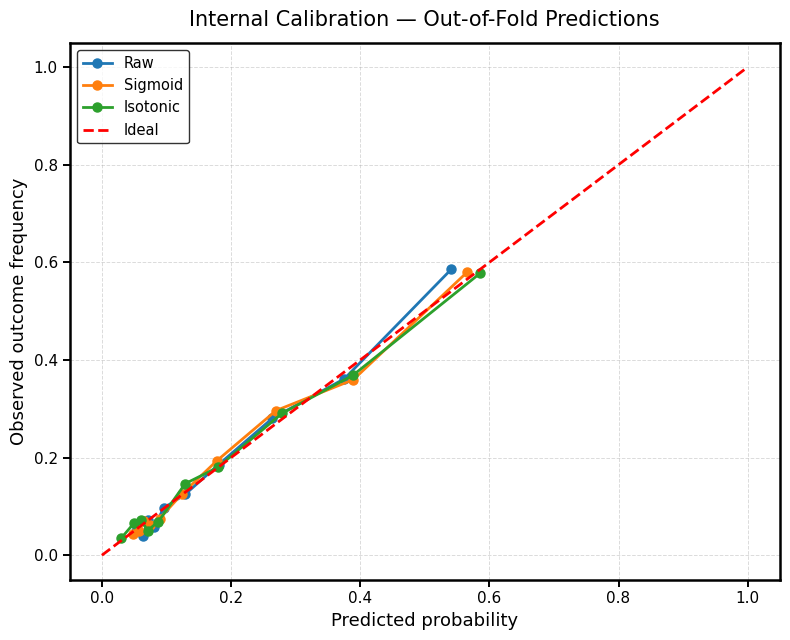


Completed in 9.1 seconds.


9.138702630996704

In [ ]:
banner("EXPERIMENT 5: Raw vs sigmoid vs isotonic calibration")
t0 = time.time()

runner.calibrate_model()

finish_block(t0)

In [ ]:
banner("EXPERIMENT 6: Freeze the screening threshold")
t0 = time.time()

runner.freeze_threshold()

print("Frozen threshold:", runner.get("SCREENING_THRESHOLD"))

finish_block(t0)


EXPERIMENT 6: Freeze the screening threshold
Frozen screening threshold: 0.123898
roc_auc        0.7864
pr_auc         0.4833
brier          0.1224
log_loss       0.3932
accuracy       0.6646
precision      0.3323
sensitivity    0.8009
specificity    0.6336
f1             0.4697
dtype: float64
Frozen threshold: 0.12389798647763042

Completed in 1.0 seconds.


1.025022268295288

In [ ]:
banner("FINAL MODEL: Fit the frozen calibrated probability model")
t0 = time.time()

runner.fit_final_model()

finish_block(t0)


FINAL MODEL: Fit the frozen calibrated probability model
Final frozen model fitted.

Completed in 1.3 seconds.


1.3414721488952637

In [ ]:
banner("TEMPORAL DATA: Build NHANES 2021–2023 validation cohort")
t0 = time.time()

runner.build_temporal_cohort()

finish_block(t0)


TEMPORAL DATA: Build NHANES 2021–2023 validation cohort
Linked temporal source participants: 7,199
Excluded age <18: 862
Adults after age filter: 6,337
Excluded for missing serum creatinine or urinary ACR: 785
Temporal validation cohort retained: 5,552
Temporal phenotype-positive cases: 949
Temporal unweighted phenotype prevalence: 0.170929
Temporal validation n: 5552
Temporal survey weight: WTPH2YR
Positive temporal weights: 5552
Unweighted prevalence: 0.1709
Survey-weighted prevalence: 0.1391

Completed in 5.7 seconds.


5.73918604850769

In [ ]:
banner("EXPERIMENT 7: Temporal validation")
t0 = time.time()

runner.run_temporal_validation()

finish_block(t0)


EXPERIMENT 7: Temporal validation
Unweighted temporal performance


,estimate
roc_auc,0.7949
pr_auc,0.4830
brier,0.1142
log_loss,0.3715
accuracy,0.6416
precision,0.3003
sensitivity,0.8251
specificity,0.6037
f1,0.4404


Survey-weighted temporal performance


,estimate
roc_auc,0.7987
pr_auc,0.4549
brier,0.0968
log_loss,0.3255
accuracy,0.7105
precision,0.2933
sensitivity,0.7671
specificity,0.7014
f1,0.4243


,metric,estimate,ci_low_95,ci_high_95
0,roc_auc,0.7949,0.7786,0.8107
1,pr_auc,0.4830,0.4499,0.5148
2,brier,0.1142,0.1088,0.1196
3,log_loss,0.3715,0.3570,0.3862
4,accuracy,0.6416,0.6290,0.6542
5,precision,0.3003,0.2828,0.3182
6,sensitivity,0.8251,0.7988,0.8481
7,specificity,0.6037,0.5896,0.6176
8,f1,0.4404,0.4201,0.4605



Completed in 37.4 seconds.


37.43631863594055

In [ ]:
banner("REPRODUCTION CHECK 2: frozen model and temporal validation")
published = {
    "selected model": ("HistGradientBoosting", runner.get("SELECTED_MODEL_NAME")),
    "calibration":    ("Sigmoid", runner.get("BEST_CALIBRATION")),
    "threshold":      (0.1239, round(float(runner.get("SCREENING_THRESHOLD")), 4)),
    "temporal AUC":   (0.7949, round(float(runner.get("temporal_unweighted")["roc_auc"]), 4)),
    "temporal sens":  (0.8251, round(float(runner.get("temporal_unweighted")["sensitivity"]), 4)),
    "temporal spec":  (0.6037, round(float(runner.get("temporal_unweighted")["specificity"]), 4)),
    "weighted sens":  (0.7671, round(float(runner.get("temporal_weighted")["sensitivity"]), 4)),
}
all_match = True
for name, (pub, new_val) in published.items():
    ok = pub == new_val
    all_match &= ok
    print(f"{name:<15} published {pub} | this run {new_val} | {'MATCH' if ok else 'DIFFERENT'}")
print("\nREPRODUCTION CHECK 2:", "PASSED" if all_match else "FAILED")
if REQUIRE_EXACT_REPRODUCTION and not all_match:
    raise RuntimeError("Frozen model does not reproduce the published results. Stopping.")


REPRODUCTION CHECK 2: frozen model and temporal validation
selected model  published HistGradientBoosting | this run HistGradientBoosting | MATCH
calibration     published Sigmoid | this run Sigmoid | MATCH
threshold       published 0.1239 | this run 0.1239 | MATCH
temporal AUC    published 0.7949 | this run 0.7949 | MATCH
temporal sens   published 0.8251 | this run 0.8251 | MATCH
temporal spec   published 0.6037 | this run 0.6037 | MATCH
weighted sens   published 0.7671 | this run 0.7671 | MATCH

REPRODUCTION CHECK 2: PASSED



EXPERIMENT 8: Temporal calibration transport
Temporal calibration
{'brier': np.float64(0.11418077245298676), 'calibration_intercept': 0.09698530070956156, 'calibration_slope': 1.1405778139700833, 'ece': 0.016861165282916597}
Survey-weighted calibration sensitivity
{'brier': np.float64(0.09676492722300052), 'ece': 0.014833205177868599}


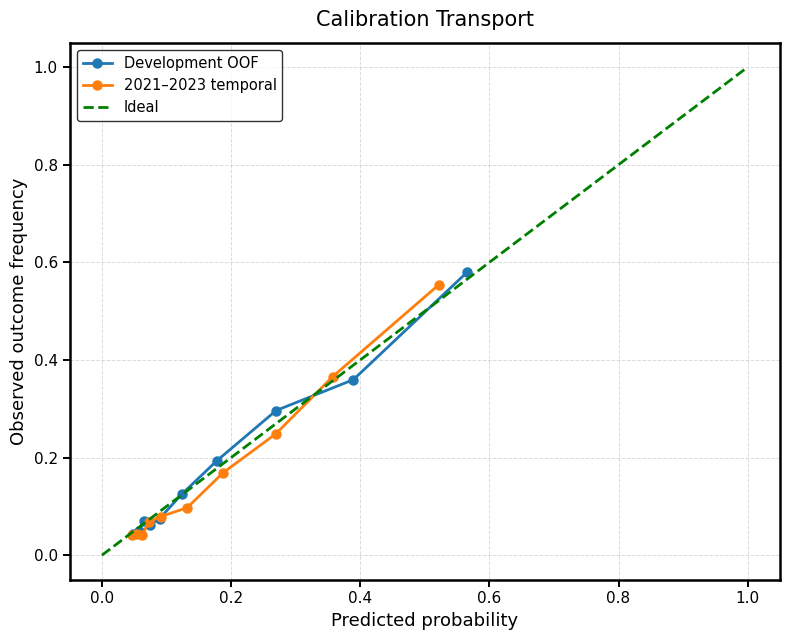


Completed in 2.4 seconds.


2.4362716674804688

In [ ]:
banner("EXPERIMENT 8: Temporal calibration transport")
t0 = time.time()

runner.run_temporal_calibration()

finish_block(t0)


EXPERIMENT 9: Decision-curve analysis


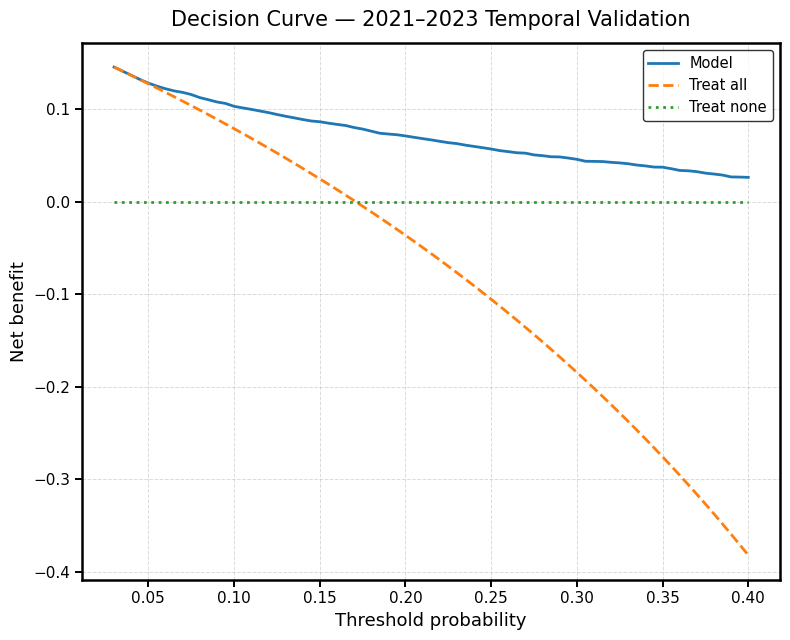


Completed in 2.6 seconds.


2.5981767177581787

In [ ]:
banner("EXPERIMENT 9: Decision-curve analysis")
t0 = time.time()

runner.run_decision_curve()

finish_block(t0)

In [ ]:
banner("EXPERIMENT 10: Age-removal sensitivity")
t0 = time.time()

runner.run_age_sensitivity()

finish_block(t0)


EXPERIMENT 10: Age-removal sensitivity


,analysis,internal_auc,temporal_auc
0,Primary model,0.7864,0.7949
1,Age removed,0.7576,0.7515



Completed in 178.1 seconds.


178.06258487701416

In [ ]:
banner("EXPERIMENT 11: Low-eGFR vs albuminuria components")
t0 = time.time()

runner.run_outcome_component_sensitivity()

finish_block(t0)


EXPERIMENT 11: Low-eGFR vs albuminuria components


,outcome,prevalence,roc_auc,pr_auc,brier
0,low_egfr,0.0818,0.8501,0.3202,0.0751
1,albuminuria,0.1149,0.7441,0.3138,0.0985
2,ckd,0.1709,0.7949,0.4830,0.1142



Completed in 1.5 seconds.


1.4938247203826904

In [ ]:
banner("EXPERIMENT 12: Race and physical-activity feature-set sensitivity")
t0 = time.time()

runner.run_feature_set_sensitivity()

finish_block(t0)


EXPERIMENT 12: Race and physical-activity feature-set sensitivity


,feature_set,roc_auc,pr_auc,brier,log_loss
0,Primary,0.7800,0.4750,0.1238,0.3983
1,Primary_plus_race,0.7836,0.4821,0.1229,0.3957
2,Primary_plus_activity,0.7800,0.4752,0.1238,0.3982



Completed in 299.4 seconds.


299.41072964668274

In [ ]:
banner("EXPERIMENT 13: Temporal subgroup performance and calibration")
t0 = time.time()

runner.run_subgroup_analysis()

finish_block(t0)


EXPERIMENT 13: Temporal subgroup performance and calibration


,variable,subgroup,n,cases,controls,status,roc_auc,roc_auc_ci_low,roc_auc_ci_high,sensitivity,sensitivity_ci_low,sensitivity_ci_high,specificity,specificity_ci_low,specificity_ci_high,pr_auc,pr_auc_ci_low,pr_auc_ci_high
0,RIAGENDR,female,3037,493,2544,evaluated,0.7710,0.7469,0.7938,0.7911,0.7535,0.8279,0.6101,0.5919,0.6280,0.4405,0.3973,0.4854
1,RIAGENDR,male,2515,456,2059,evaluated,0.8199,0.7989,0.8401,0.8618,0.8304,0.8930,0.5959,0.5757,0.6167,0.5339,0.4876,0.5758
2,RIDRETH1,mexican_american,392,48,344,evaluated,0.7206,0.6352,0.7995,0.6667,0.5227,0.8000,0.7151,0.6666,0.7625,0.3419,0.2305,0.4916
3,RIDRETH1,non_hispanic_black,645,157,488,evaluated,0.7994,0.7600,0.8353,0.8280,0.7707,0.8862,0.5738,0.5288,0.6162,0.5741,0.4937,0.6525
4,RIDRETH1,non_hispanic_white,3286,556,2730,evaluated,0.8039,0.7822,0.8238,0.8597,0.8299,0.8891,0.5762,0.5577,0.5944,0.4848,0.4450,0.5302
5,RIDRETH1,other_hispanic,580,79,501,evaluated,0.7463,0.6871,0.8028,0.6835,0.5833,0.7875,0.6507,0.6078,0.6892,0.4033,0.2976,0.5156
6,RIDRETH1,other_or_multiracial,649,109,540,evaluated,0.8072,0.7596,0.8544,0.8165,0.7400,0.8880,0.6556,0.6158,0.6951,0.5158,0.4146,0.6191
7,age_group,18-39,1562,88,1474,evaluated,0.6302,0.5628,0.6910,0.2273,0.1461,0.3119,0.9579,0.9474,0.9680,0.1845,0.1171,0.2724
8,age_group,40-59,1557,183,1374,evaluated,0.7175,0.6761,0.7562,0.6066,0.5346,0.6700,0.7249,0.7023,0.7482,0.3142,0.2459,0.3860
9,age_group,60+,2433,678,1755,evaluated,0.7593,0.7365,0.7786,0.9617,0.9470,0.9753,0.2114,0.1922,0.2313,0.5460,0.5089,0.5833


,variable,subgroup,n,cases,controls,status,brier,calibration_intercept,calibration_slope,ece
0,RIAGENDR,female,3037,493,2544,evaluated,0.1137,-0.0558,1.0341,0.0134
1,RIAGENDR,male,2515,456,2059,evaluated,0.1148,0.2687,1.2747,0.0311
2,age_group,18-39,1562,88,1474,evaluated,0.0510,0.9044,1.4412,0.0185
3,age_group,40-59,1557,183,1374,evaluated,0.0941,0.0727,1.0535,0.0178
4,age_group,60+,2433,678,1755,evaluated,0.1676,0.1376,1.2723,0.0311
5,has_diabetes_dx,no,4618,587,4031,evaluated,0.0962,-0.0299,1.0798,0.0184
6,has_diabetes_dx,yes,743,317,426,evaluated,0.2156,0.2405,1.3462,0.0517
7,has_diabetes_dx,nan,191,45,146,evaluated,0.1555,0.3212,1.1421,0.0621
8,has_htn_dx,no,3541,342,3199,evaluated,0.0802,-0.1248,1.0120,0.0131
9,has_htn_dx,yes,2008,607,1401,evaluated,0.1741,0.2174,1.3261,0.0395



Completed in 183.6 seconds.


183.60072922706604

In [ ]:
banner("EXPERIMENT 14: Age- and diabetes-stratified thresholds")
t0 = time.time()

runner.run_stratified_thresholds()

finish_block(t0)


EXPERIMENT 14: Age- and diabetes-stratified thresholds
[18-39] development n=1694, frozen threshold=0.056258, dev sensitivity=0.8000, dev specificity=0.3148
[40-59] development n=1542, frozen threshold=0.094830, dev sensitivity=0.8030, dev specificity=0.5536
[60+] development n=1827, frozen threshold=0.269368, dev sensitivity=0.8019, dev specificity=0.5154

Frozen age-stratified thresholds (development OOF only):
{'18-39': 0.05625826722236723, '40-59': 0.09482950186510727, '60+': 0.26936761405207577}


,age_group,n,cases,global_threshold,global_sensitivity,global_specificity,stratified_threshold,stratified_sensitivity,stratified_specificity
0,18-39,1562,88,0.1239,0.2273,0.9579,0.0563,0.6591,0.4206
1,40-59,1557,183,0.1239,0.6066,0.7249,0.0948,0.6721,0.6266
2,60+,2433,678,0.1239,0.9617,0.2114,0.2694,0.7847,0.5983



Pooled temporal performance under age-stratified thresholds: sensitivity=0.7513, specificity=0.5499
Pooled temporal performance under the single global threshold: sensitivity=0.8251, specificity=0.6037
[diabetes=no] development n=4133, frozen threshold=0.082356, dev sensitivity=0.8010, dev specificity=0.5511
[diabetes=yes] development n=770, frozen threshold=0.322936, dev sensitivity=0.8036, dev specificity=0.3986


,diabetes_dx,n,cases,global_threshold,global_sensitivity,global_specificity,stratified_threshold,stratified_sensitivity,stratified_specificity
0,no,4618,587,0.1239,0.724,0.6755,0.0824,0.8041,0.5413
1,yes,743,317,0.1239,1.000,0.0000,0.3229,0.8044,0.4178



Completed in 1.1 seconds.


1.1192598342895508

In [ ]:
banner("EXPERIMENT 15: Class weighting, SMOTE, and SMOTEENN")
t0 = time.time()

runner.run_imbalance_sensitivity()

finish_block(t0)


EXPERIMENT 15: Class weighting, SMOTE, and SMOTEENN


,strategy,roc_auc,pr_auc,brier,log_loss
0,none,0.7662,0.4482,0.1293,0.4206
1,smote,0.7586,0.4282,0.1389,0.4382
2,smoteenn,0.7698,0.4578,0.2013,0.6989
3,class_weight,0.7635,0.4436,0.1563,0.4831



Completed in 4.0 seconds.


3.9998514652252197

In [ ]:
banner("EXPERIMENT 16: Survey-weighted evaluation")
t0 = time.time()

runner.run_survey_weighted_evaluation()

finish_block(t0)


EXPERIMENT 16: Survey-weighted evaluation


,cohort,survey_weight,roc_auc,pr_auc,brier,log_loss,accuracy,precision,sensitivity,specificity,f1
0,2017-2018 development OOF,WTMEC2YR,0.7809,0.4189,0.0984,0.3316,0.7123,0.2880,0.7387,0.7081,0.4144
1,2021-2023 temporal,WTPH2YR,0.7987,0.4549,0.0968,0.3255,0.7105,0.2933,0.7671,0.7014,0.4243



Completed in 1.5 seconds.


1.4957914352416992


EXPERIMENT 17: Temporal permutation importance


,feature,importance_mean,importance_sd
0,RIDAGEYR,0.1151,0.0063
5,has_diabetes_dx,0.0307,0.0028
4,has_htn_dx,0.0158,0.0028
10,mean_sbp,0.0098,0.0017
3,INDFMPIR,0.0039,0.0014
6,BMXBMI,0.0028,0.0008
11,mean_dbp,0.0014,0.0003
2,DMDEDUC2,0.0008,0.0004
1,RIAGENDR,0.0004,0.0002
7,BMXWAIST,0.0002,0.0004


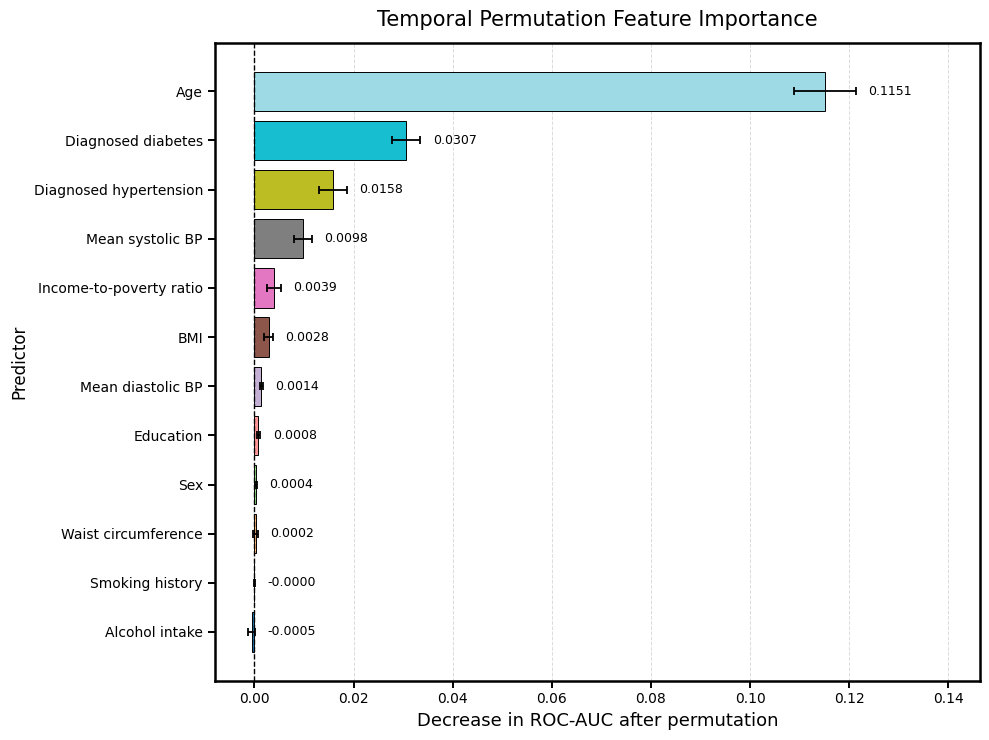


Completed in 43.3 seconds.


43.25684571266174

In [ ]:
banner("EXPERIMENT 17: Temporal permutation importance")
t0 = time.time()

runner.run_permutation_importance()

finish_block(t0)

In [ ]:
banner("FINAL OUTPUTS: Reproducibility record and master tables")
t0 = time.time()

runner.finalize_outputs()

finish_block(t0)


FINAL OUTPUTS: Reproducibility record and master tables


,cohort,roc_auc,pr_auc,brier,log_loss,accuracy,precision,sensitivity,specificity,f1
0,2017-2018 internal OOF,0.7864,0.4833,0.1224,0.3932,0.6646,0.3323,0.8009,0.6336,0.4697
1,2021-2023 temporal validation,0.7949,0.4830,0.1142,0.3715,0.6416,0.3003,0.8251,0.6037,0.4404



All outputs saved to:
/content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results

=== FINAL REVISED SURVEY-WEIGHTED RESULTS ===


,cohort,survey_weight,roc_auc,pr_auc,brier,log_loss,accuracy,precision,sensitivity,specificity,f1
0,2017-2018 development OOF,WTMEC2YR,0.7809,0.4189,0.0984,0.3316,0.7123,0.2880,0.7387,0.7081,0.4144
1,2021-2023 temporal,WTPH2YR,0.7987,0.4549,0.0968,0.3255,0.7105,0.2933,0.7671,0.7014,0.4243



Development weighted prevalence (WTMEC2YR): 0.1378
Temporal weighted prevalence (WTPH2YR): 0.1391

Temporal weighted calibration:
{'brier': np.float64(0.0968), 'ece': 0.0148}

All results are saved in: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results

Completed in 0.9 seconds.


0.9389655590057373

## 5. Reviewer-revision analyses (modules 26–39)

In [ ]:
banner("REVISION SETUP: Helpers, survey design, revision output folder")
t0 = time.time()

runner.revision_setup()

finish_block(t0)


REVISION SETUP: Helpers, survey design, revision output folder
Revision outputs directory: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/revision_round1
Development design: strata = 15 | PSUs = 17
Temporal design:    strata = 15 | PSUs = 17
Revision helpers loaded.

Completed in 0.8 seconds.


0.8298988342285156

In [ ]:
banner("REVISION A: Prevalence n/N, included vs excluded, outcome components (R2.2, R2.6, R3m2)")
t0 = time.time()

runner.run_cohort_description()

finish_block(t0)


REVISION A: Prevalence n/N, included vs excluded, outcome components (R2.2, R2.6, R3m2)
2017-2018 adults with laboratory records: 5533
  excluded for missing creatinine/ACR: 470
  retained: 5063
Integrity check passed: rebuilt retained set = analytic cohort.
Development phenotype mismatches after rebuild: 0


,cohort,outcome,n_positive,N,n_over_N,unweighted_pct,survey_weighted_pct,survey_weight
0,2017-2018 development,CKD screening phenotype,939,5063,"939/5,063",18.55,13.78,WTMEC2YR
1,2017-2018 development,Reduced eGFR (<60),411,5063,"411/5,063",8.12,5.51,WTMEC2YR
2,2017-2018 development,Albuminuria (ACR >=30 mg/g),686,5063,"686/5,063",13.55,9.91,WTMEC2YR
3,2017-2018 development,Both components,158,5063,"158/5,063",3.12,1.64,WTMEC2YR
4,2021-2023 temporal,CKD screening phenotype,949,5552,"949/5,552",17.09,13.91,WTPH2YR
5,2021-2023 temporal,Reduced eGFR (<60),454,5552,"454/5,552",8.18,6.02,WTPH2YR
6,2021-2023 temporal,Albuminuria (ACR >=30 mg/g),638,5552,"638/5,552",11.49,9.86,WTPH2YR
7,2021-2023 temporal,Both components,143,5552,"143/5,552",2.58,1.97,WTPH2YR


,cohort,characteristic,included,excluded,smd
0,2017-2018 development,N,"5,063",470,NaN
1,2017-2018 development,"Age, years (mean ± SD)",49.7 ± 18.5,50.7 ± 20.2,-0.050
2,2017-2018 development,Income-to-poverty ratio (mean ± SD),2.5 ± 1.6,2.5 ± 1.6,0.026
3,2017-2018 development,"BMI, kg/m2 (mean ± SD)",29.7 ± 7.4,29.0 ± 8.2,0.090
4,2017-2018 development,"Waist circumference, cm (mean ± SD)",100.3 ± 17.2,98.2 ± 17.6,0.119
5,2017-2018 development,"Mean systolic BP, mmHg (mean ± SD)",126.2 ± 19.8,128.4 ± 23.8,-0.102
6,2017-2018 development,"Mean diastolic BP, mmHg (mean ± SD)",72.2 ± 12.8,71.2 ± 14.5,0.076
7,2017-2018 development,"Female, %",51.9,49.8,0.042
8,2017-2018 development,"Diagnosed hypertension, %",36.5,38.5,-0.043
9,2017-2018 development,"Diagnosed diabetes, %",15.7,14.8,0.027


Largest absolute standardized difference: 0.334 (|SMD| < 0.10 is conventionally regarded as negligible).

Completed in 7.6 seconds.


7.610803604125977

In [ ]:
banner("REVISION B: One-SE rule, calibration methods, calibrated family comparison, fully nested procedure (R1.2, R2.4, R2.5, R3.1, R3m1, R4.5)")
t0 = time.time()

runner.run_model_selection_revision()

finish_block(t0)


REVISION B: One-SE rule, calibration methods, calibrated family comparison, fully nested procedure (R1.2, R2.4, R2.5, R3.1, R3m1, R4.5)
Best-AUC model: Random Forest
Outer-fold AUCs: [0.7674 0.7978 0.7938 0.7772 0.8031]
SD = 0.0150; SE = SD / sqrt(5) = 0.0067; cutoff = 0.7879 - 0.0067 = 0.7812


,model,mean_roc_auc,sd_roc_auc,se_roc_auc,mean_brier,mean_log_loss,best_model_mean_auc,best_model_se_auc,one_se_cutoff,in_competitive_set,selected
0,Random Forest,0.7879,0.0150,0.0067,0.1297,0.4115,0.7879,0.0067,0.7812,True,False
1,XGBoost,0.7871,0.0200,0.0089,0.1320,0.4173,0.7879,0.0067,0.7812,True,False
2,HistGradientBoosting,0.7819,0.0199,0.0089,0.1237,0.3973,0.7879,0.0067,0.7812,True,True
3,LightGBM,0.7817,0.0201,0.0090,0.1572,0.4823,0.7879,0.0067,0.7812,True,False
4,Logistic Regression,0.7808,0.0164,0.0073,0.1364,0.4306,0.7879,0.0067,0.7812,False,False


{
  "table": "Table 2 (nested cross-validation model comparison)",
  "unit_of_resampling": "outer cross-validation fold (k = 5)",
  "interval": "mean \u00b1 t(0.975, df = 4) \u00d7 SD / sqrt(5)",
  "t_critical_value": 2.7764451051977987,
  "interpretation": "Describes variability of performance across the five outer test folds; folds share training data, so the interval is approximate and likely somewhat narrow (Bengio & Grandvalet, 2004).",
  "source_file": "nested_cv_outer_fold_summary_CI.csv (module 07)"
}


,comparison,metric,difference,ci_low_95,ci_high_95,ci_includes_zero
0,Sigmoid - Isotonic,roc_auc,-0.00020,-0.00151,0.00115,True
1,Sigmoid - Isotonic,brier,-0.00004,-0.00044,0.00038,True
2,Sigmoid - Isotonic,log_loss,-0.00642,-0.02079,0.00137,True
3,Sigmoid - Isotonic,ece,0.00034,-0.00690,0.00814,True
4,Sigmoid - Raw,roc_auc,0.00086,-0.00057,0.00231,True
5,Sigmoid - Raw,brier,-0.00030,-0.00067,0.00010,True
6,Sigmoid - Raw,log_loss,-0.00117,-0.00221,-0.00012,False
7,Sigmoid - Raw,ece,-0.00055,-0.00855,0.00571,True
8,Isotonic - Raw,roc_auc,0.00106,-0.00078,0.00291,True
9,Isotonic - Raw,brier,-0.00026,-0.00090,0.00038,True



=== Calibrated comparison: Logistic Regression ===
fold 1: Raw AUC=0.768 Brier=0.1253 | Sigmoid AUC=0.768 Brier=0.1252 | Isotonic AUC=0.768 Brier=0.1262
fold 2: Raw AUC=0.794 Brier=0.1870 | Sigmoid AUC=0.793 Brier=0.1230 | Isotonic AUC=0.794 Brier=0.1241
fold 3: Raw AUC=0.778 Brier=0.1241 | Sigmoid AUC=0.778 Brier=0.1239 | Isotonic AUC=0.779 Brier=0.1244
fold 4: Raw AUC=0.763 Brier=0.1239 | Sigmoid AUC=0.763 Brier=0.1240 | Isotonic AUC=0.765 Brier=0.1231
fold 5: Raw AUC=0.801 Brier=0.1216 | Sigmoid AUC=0.802 Brier=0.1214 | Isotonic AUC=0.802 Brier=0.1215

=== Calibrated comparison: Random Forest ===
fold 1: Raw AUC=0.767 Brier=0.1569 | Sigmoid AUC=0.768 Brier=0.1242 | Isotonic AUC=0.769 Brier=0.1251
fold 2: Raw AUC=0.798 Brier=0.1233 | Sigmoid AUC=0.798 Brier=0.1251 | Isotonic AUC=0.792 Brier=0.1247
fold 3: Raw AUC=0.794 Brier=0.1226 | Sigmoid AUC=0.793 Brier=0.1213 | Isotonic AUC=0.791 Brier=0.1220
fold 4: Raw AUC=0.777 Brier=0.1249 | Sigmoid AUC=0.778 Brier=0.1229 | Isotonic AUC=0.7

,calibration,model,mean_roc_auc,sd_roc_auc,mean_pr_auc,mean_brier,sd_brier,mean_log_loss,mean_ece,mean_calibration_slope,se_roc_auc
0,Isotonic,HistGradientBoosting,0.7857,0.0196,0.4784,0.1232,0.0029,0.3963,0.0294,0.9547,0.0088
1,Isotonic,LightGBM,0.7843,0.0208,0.4820,0.1233,0.0031,0.4033,0.0322,0.9264,0.0093
2,Isotonic,Logistic Regression,0.7813,0.0162,0.4731,0.1239,0.0017,0.4106,0.0249,0.9026,0.0072
3,Isotonic,Random Forest,0.7863,0.0141,0.4807,0.1231,0.0021,0.4083,0.0325,0.8954,0.0063
4,Isotonic,XGBoost,0.7878,0.0212,0.4884,0.1223,0.0034,0.4065,0.0279,0.9211,0.0095
5,Raw,HistGradientBoosting,0.7819,0.0199,0.4775,0.1237,0.0023,0.3973,0.0294,1.0533,0.0089
6,Raw,LightGBM,0.7817,0.0201,0.4779,0.1572,0.0328,0.4823,0.1430,1.0487,0.0090
7,Raw,Logistic Regression,0.7808,0.0164,0.4799,0.1364,0.0283,0.4306,0.0723,1.0822,0.0073
8,Raw,Random Forest,0.7879,0.0150,0.4838,0.1297,0.0153,0.4115,0.0576,1.1941,0.0067
9,Raw,XGBoost,0.7871,0.0200,0.4908,0.1320,0.0223,0.4173,0.0629,1.0336,0.0089


... (2 outputs left out)

,fold,fold_threshold,roc_auc,pr_auc,brier,log_loss,accuracy,precision,sensitivity,specificity,f1,ece,calibration_intercept,calibration_slope
0,1,0.1395,0.7646,0.4880,0.1238,0.4027,0.6851,0.3391,0.7340,0.6739,0.4639,0.0272,0.0053,0.9622
1,2,0.1231,0.7979,0.4648,0.1234,0.3925,0.6713,0.3385,0.8085,0.6400,0.4772,0.0293,0.0547,1.0450
2,3,0.1281,0.7877,0.4693,0.1218,0.3917,0.6752,0.3430,0.8191,0.6424,0.4835,0.0232,0.0003,1.0334
3,4,0.1208,0.7653,0.4551,0.1260,0.4038,0.6532,0.3248,0.8128,0.6170,0.4641,0.0344,-0.0216,0.9555
4,5,0.1292,0.8105,0.5181,0.1192,0.3825,0.6640,0.3390,0.8511,0.6214,0.4848,0.0334,0.2175,1.2252


,estimate,roc_auc,brier,sensitivity,specificity,threshold
0,Reported internal OOF (hyperparameters tuned o...,0.7864,0.1224,0.8009,0.6336,0.1239
1,"Fully nested (tuning, calibration and threshol...",0.7852,0.1229,0.8051,0.6389,0.1282
2,Fully nested — pooled outer-fold predictions,0.7839,0.1229,0.8051,0.6389,NaN


Optimism of reported internal AUC relative to the fully nested estimate: +0.0012

Completed in 170.1 seconds.


170.11071848869324


REVISION C: Calibrated LR, reduced predictor sets, risk-factor rules, testing burden (R1, R1.1, R4.1)
[Calibrated logistic regression (12 predictors)] dev OOF AUC=0.7810 | temporal AUC=0.7803 | frozen threshold=0.1462
[Calibrated logistic regression (age, diabetes, hypertension)] dev OOF AUC=0.7748 | temporal AUC=0.7740 | frozen threshold=0.1524
[HistGradientBoosting A1: age + diabetes + hypertension] dev OOF AUC=0.7671 | temporal AUC=0.7792 | frozen threshold=0.1196
[HistGradientBoosting A2: A1 + systolic/diastolic BP] dev OOF AUC=0.7744 | temporal AUC=0.7849 | frozen threshold=0.1265
[HistGradientBoosting A3: A2 + BMI + waist] dev OOF AUC=0.7844 | temporal AUC=0.7917 | frozen threshold=0.1277
[HistGradientBoosting A4: A3 + sex] dev OOF AUC=0.7784 | temporal AUC=0.7858 | frozen threshold=0.1326


,model,frozen_threshold,dev_roc_auc,dev_brier,temporal_roc_auc,temporal_pr_auc,temporal_brier,temporal_cal_intercept,temporal_cal_slope,temporal_ece,temporal_sensitivity,temporal_specificity,temporal_weighted_sensitivity,temporal_weighted_specificity,n_predictors
0,"HistGradientBoosting (primary, 12 predictors)",0.1239,0.7864,0.1224,0.7949,0.4830,0.1142,0.0970,1.1406,0.0169,0.8251,0.6037,0.7671,0.7014,12
1,Calibrated logistic regression (12 predictors),0.1462,0.7810,0.1234,0.7803,0.4617,0.1173,0.1336,1.1096,0.0180,0.8114,0.6235,0.7454,0.7271,12
2,"Calibrated logistic regression (age, diabetes,...",0.1524,0.7748,0.1253,0.7740,0.4415,0.1192,-0.0768,1.0915,0.0333,0.8198,0.5588,0.7468,0.6743,3
3,HistGradientBoosting A1: age + diabetes + hype...,0.1196,0.7671,0.1254,0.7792,0.4480,0.1174,-0.0275,1.1039,0.0237,0.8272,0.5518,0.7692,0.6563,3
4,HistGradientBoosting A2: A1 + systolic/diastol...,0.1265,0.7744,0.1238,0.7849,0.4776,0.1150,0.0896,1.1556,0.0205,0.8230,0.6024,0.7617,0.7006,5
5,HistGradientBoosting A3: A2 + BMI + waist,0.1277,0.7844,0.1230,0.7917,0.4792,0.1146,0.0629,1.1349,0.0176,0.8124,0.6153,0.7509,0.7135,7
6,HistGradientBoosting A4: A3 + sex,0.1326,0.7784,0.1243,0.7858,0.4679,0.1160,0.1213,1.1810,0.0241,0.8156,0.5966,0.7669,0.6930,8


Burden matched to 'Rule: diabetes or hypertension': dev positive rate=0.412, frozen model threshold=0.1410
Burden matched to 'Rule: diabetes, hypertension, or age >=60': dev positive rate=0.529, frozen model threshold=0.0930


,weighting,strategy,sensitivity,specificity,ppv,npv,positive_rate,tests_per_1000,cases_found_per_1000,cases_missed_per_1000,tests_per_case_found,additional_cases_vs_dm_htn_rule_per_1000,additional_tests_vs_dm_htn_rule_per_1000
0,unweighted,"HistGradientBoosting (primary, 12 predictors)",0.825,0.604,0.300,0.944,0.470,469.561,141.030,29.899,3.330,21.794,69.885
1,survey-weighted (WTPH2YR),"HistGradientBoosting (primary, 12 predictors)",0.767,0.701,0.293,0.949,0.364,363.754,106.676,32.379,3.410,13.885,27.953
2,unweighted,Calibrated logistic regression (12 predictors),0.811,0.624,0.308,0.941,0.451,450.829,138.689,32.241,3.251,19.452,51.153
3,survey-weighted (WTPH2YR),Calibrated logistic regression (12 predictors),0.745,0.727,0.306,0.946,0.339,338.598,103.659,35.397,3.266,10.868,2.797
4,unweighted,"Calibrated logistic regression (age, diabetes,...",0.820,0.559,0.277,0.938,0.506,505.944,140.130,30.800,3.611,20.893,106.268
5,survey-weighted (WTPH2YR),"Calibrated logistic regression (age, diabetes,...",0.747,0.674,0.270,0.943,0.384,384.252,103.853,35.203,3.700,11.062,48.450
6,unweighted,HistGradientBoosting A1: age + diabetes + hype...,0.827,0.552,0.276,0.939,0.513,512.968,141.390,29.539,3.628,22.154,113.293
7,survey-weighted (WTPH2YR),HistGradientBoosting A1: age + diabetes + hype...,0.769,0.656,0.266,0.946,0.403,402.875,106.968,32.088,3.766,14.177,67.074
8,unweighted,HistGradientBoosting A2: A1 + systolic/diastol...,0.823,0.602,0.299,0.943,0.470,470.281,140.670,30.259,3.343,21.434,70.605
9,survey-weighted (WTPH2YR),HistGradientBoosting A2: A1 + systolic/diastol...,0.762,0.701,0.291,0.948,0.364,363.677,105.918,33.138,3.434,13.127,27.876


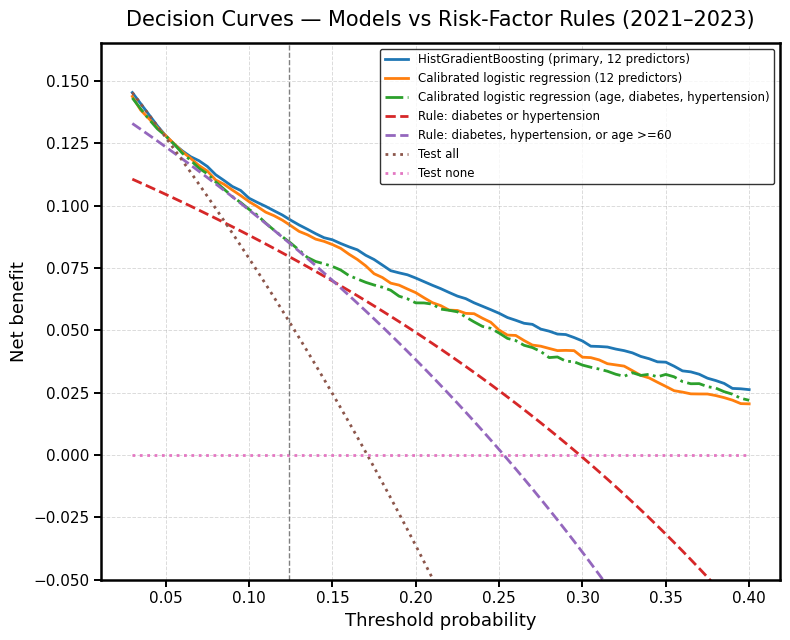

,contrast,quantity,difference,ci_low_95,ci_high_95
0,Primary minus Calibrated logistic regression (...,auc,0.0146,0.0081,0.0209
1,Primary minus Calibrated logistic regression (...,brier,-0.0031,-0.0045,-0.0018
2,Primary minus Calibrated logistic regression (...,auc,0.0209,0.0138,0.0284
3,Primary minus Calibrated logistic regression (...,brier,-0.0050,-0.0064,-0.0037
4,Primary minus HistGradientBoosting A1: age + d...,auc,0.0157,0.0095,0.0228
5,Primary minus HistGradientBoosting A1: age + d...,brier,-0.0032,-0.0043,-0.0022
6,Primary minus HistGradientBoosting A4: A3 + sex,auc,0.0092,0.0038,0.0147
7,Primary minus HistGradientBoosting A4: A3 + sex,brier,-0.0019,-0.0029,-0.0009
8,Primary minus Rule: diabetes or hypertension,net_benefit_at_frozen_threshold,0.0150,0.0105,0.0197
9,Primary minus Rule: diabetes or hypertension,burden_matched_sensitivity,0.1001,0.0759,0.1247



Completed in 147.3 seconds.


147.30556178092957

In [ ]:
banner("REVISION C: Calibrated LR, reduced predictor sets, risk-factor rules, testing burden (R1, R1.1, R4.1)")
t0 = time.time()

runner.run_comparators_and_ablation()

finish_block(t0)


REVISION D: Survey-weighted 80% sensitivity threshold (R1.3, R2.7, R3.3, R4.4)
Unweighted threshold (module 11):          0.123898
Same rule re-derived with unit weights:   0.123898
Survey-weighted 80%-sensitivity threshold: 0.094830
Unit-weight check: same operating point as module 11 (OK).


,cohort,threshold_rule,threshold,unweighted_sensitivity,unweighted_specificity,unweighted_ppv,unweighted_npv,unweighted_positive_rate,weighted_sensitivity,weighted_specificity,weighted_ppv,weighted_npv,weighted_positive_rate,weighted_sensitivity_design_ci_low,weighted_sensitivity_design_ci_high,weighted_specificity_design_ci_low,weighted_specificity_design_ci_high,weighted_ppv_design_ci_low,weighted_ppv_design_ci_high,weighted_positive_rate_design_ci_low,weighted_positive_rate_design_ci_high
0,2017-2018 development OOF,Current (unweighted 80% target),0.1239,0.8009,0.6336,0.3323,0.9332,0.4470,0.7387,0.7081,0.2880,0.9443,0.3535,0.7148,0.7622,0.6837,0.7327,0.2728,0.3027,0.3269,0.3788
1,2017-2018 development OOF,Revised (survey-weighted 80% target),0.0948,0.8520,0.5514,0.3019,0.9424,0.5234,0.8009,0.6190,0.2515,0.9511,0.4389,0.7673,0.8351,0.5880,0.6532,0.2339,0.2695,0.4063,0.4706
2,2017-2018 development OOF,"Difference (revised - current), weighted",-0.0291,NaN,NaN,NaN,NaN,NaN,0.0622,-0.0891,-0.0365,NaN,0.0854,0.0358,0.0897,-0.1041,-0.0740,-0.0462,-0.0266,0.0723,0.0979
3,2021-2023 temporal,Current (unweighted 80% target),0.1239,0.8251,0.6037,0.3003,0.9436,0.4696,0.7671,0.7014,0.2933,0.9491,0.3638,0.7324,0.8046,0.6747,0.7265,0.2775,0.3121,0.3378,0.3924
4,2021-2023 temporal,Revised (survey-weighted 80% target),0.0948,0.8588,0.5312,0.2741,0.9480,0.5355,0.8012,0.6360,0.2623,0.9519,0.4248,0.7630,0.8419,0.6063,0.6613,0.2485,0.2784,0.3992,0.4547
5,2021-2023 temporal,"Difference (revised - current), weighted",-0.0291,NaN,NaN,NaN,NaN,NaN,0.0340,-0.0654,-0.0310,NaN,0.0610,0.0215,0.0483,-0.0730,-0.0580,-0.0386,-0.0239,0.0549,0.0675



Temporal weighted sensitivity at the survey-weighted threshold: 0.8012 (design-based 95% CI 0.7630–0.8419)


,cohort,age_group,share_of_cases_unweighted,share_of_cases_weighted,sensitivity_at_current_threshold
0,2017-2018 development OOF,18-39,0.1225,0.1663,0.1391
1,2017-2018 development OOF,40-59,0.2109,0.2685,0.6667
2,2017-2018 development OOF,60+,0.6667,0.5652,0.9649
3,2021-2023 temporal,18-39,0.0927,0.1444,0.2273
4,2021-2023 temporal,40-59,0.1928,0.2563,0.6066
5,2021-2023 temporal,60+,0.7144,0.5992,0.9617


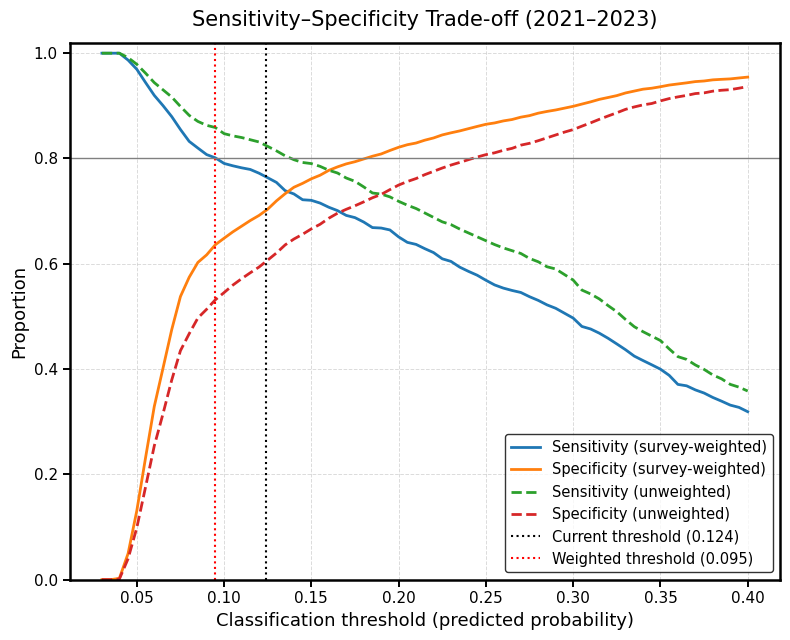


Completed in 5.4 seconds.


5.422088861465454

In [ ]:
banner("REVISION D: Survey-weighted 80% sensitivity threshold (R1.3, R2.7, R3.3, R4.4)")
t0 = time.time()

runner.run_survey_weighted_threshold()

finish_block(t0)

In [ ]:
banner("REVISION E: Survey-design-aware uncertainty, Rao-Wu bootstrap (R3.2)")
t0 = time.time()

runner.run_design_based_uncertainty()

finish_block(t0)


REVISION E: Survey-design-aware uncertainty, Rao-Wu bootstrap (R3.2)


,cohort,metric,estimate,design_ci_low,design_ci_high,design_ci_width,participant_ci_low,participant_ci_high,participant_ci_width,width_ratio_design_vs_participant
0,2017-2018 development OOF,weighted_prevalence,0.1378,0.1256,0.1495,0.0240,0.1260,0.1497,0.0238,1.0084
1,2017-2018 development OOF,weighted_roc_auc,0.7809,0.7626,0.8004,0.0379,0.7523,0.8101,0.0578,0.6557
2,2017-2018 development OOF,weighted_pr_auc,0.4189,0.3964,0.4453,0.0488,0.3806,0.4598,0.0792,0.6167
3,2017-2018 development OOF,weighted_brier,0.0984,0.0911,0.1058,0.0147,0.0906,0.1061,0.0155,0.9463
4,2017-2018 development OOF,weighted_sensitivity,0.7387,0.7148,0.7622,0.0474,0.6928,0.7857,0.0930,0.5100
5,2017-2018 development OOF,weighted_specificity,0.7081,0.6837,0.7327,0.0491,0.6875,0.7273,0.0398,1.2316
6,2017-2018 development OOF,weighted_ppv,0.2880,0.2728,0.3027,0.0300,0.2615,0.3149,0.0534,0.5617
7,2021-2023 temporal,weighted_prevalence,0.1391,0.1265,0.1539,0.0275,0.1294,0.1494,0.0200,1.3724
8,2021-2023 temporal,weighted_roc_auc,0.7987,0.7762,0.8234,0.0472,0.7763,0.8210,0.0448,1.0537
9,2021-2023 temporal,weighted_pr_auc,0.4549,0.4093,0.5024,0.0931,0.4180,0.4918,0.0738,1.2603


Median design-effect on CI width (design / participant-level): 0.98


,cohort,weight,strata,psus,replicates
0,2017-2018 development,WTMEC2YR,15,30,1000
1,2021-2023 temporal,WTPH2YR,15,30,1000



Completed in 75.5 seconds.


75.54127979278564

In [ ]:
banner("REVISION F: Calibration CIs, ECE binning, calibration near the threshold (R3.4)")
t0 = time.time()

runner.run_calibration_uncertainty()

finish_block(t0)


REVISION F: Calibration CIs, ECE binning, calibration near the threshold (R3.4)


,cohort,metric,estimate,ci_low_95,ci_high_95,ideal_value,ci_method,ci_contains_ideal
0,2017-2018 development OOF,calibration_intercept,0.0261,-0.0891,0.1469,0.0,"participant-level bootstrap, 2000 replicates",True
1,2017-2018 development OOF,calibration_slope,1.0256,0.9535,1.1014,1.0,"participant-level bootstrap, 2000 replicates",True
2,2017-2018 development OOF,calibration_in_the_large,-0.0045,-0.0812,0.0697,0.0,"participant-level bootstrap, 2000 replicates",True
3,2017-2018 development OOF,observed_expected_ratio,0.9970,0.9472,1.0471,1.0,"participant-level bootstrap, 2000 replicates",True
4,2017-2018 development OOF,ece_quantile_10,0.0132,0.0099,0.0247,0.0,"participant-level bootstrap, 2000 replicates",False
5,2021-2023 temporal,calibration_intercept,0.0970,-0.0307,0.2178,0.0,"participant-level bootstrap, 2000 replicates",True
6,2021-2023 temporal,calibration_slope,1.1406,1.0592,1.2223,1.0,"participant-level bootstrap, 2000 replicates",False
7,2021-2023 temporal,calibration_in_the_large,-0.0711,-0.1503,0.0027,0.0,"participant-level bootstrap, 2000 replicates",True
8,2021-2023 temporal,observed_expected_ratio,0.9517,0.9000,1.0019,1.0,"participant-level bootstrap, 2000 replicates",True
9,2021-2023 temporal,ece_quantile_10,0.0169,0.0125,0.0276,0.0,"participant-level bootstrap, 2000 replicates",False


,cohort,n_bins,ece_equal_frequency_bins,ece_equal_width_bins
0,2017-2018 development OOF,5,0.0090,0.0016
1,2017-2018 development OOF,10,0.0132,0.0127
2,2017-2018 development OOF,15,0.0206,0.0145
3,2017-2018 development OOF,20,0.0184,0.0203
4,2021-2023 temporal,5,0.0169,0.0154
5,2021-2023 temporal,10,0.0169,0.0166
6,2021-2023 temporal,15,0.0172,0.0201
7,2021-2023 temporal,20,0.0206,0.0204


,cohort,predicted_risk_band,contains_threshold,n,mean_predicted,observed_rate,observed_ci_low,observed_ci_high,observed_minus_predicted
0,2017-2018 development OOF,"[0.0, 0.06)",False,923,0.0516,0.0477,0.0357,0.0634,-0.0040
1,2017-2018 development OOF,"[0.06, 0.1)",False,1575,0.0749,0.0641,0.0531,0.0773,-0.0107
2,2017-2018 development OOF,"[0.1, 0.15)",True,589,0.1240,0.1392,0.1136,0.1695,0.0152
3,2017-2018 development OOF,"[0.15, 0.2)",False,347,0.1718,0.1902,0.1524,0.2348,0.0184
4,2017-2018 development OOF,"[0.2, 0.3)",False,514,0.2488,0.2626,0.2265,0.3024,0.0138
5,2017-2018 development OOF,"[0.3, 1.0)",False,1115,0.4625,0.4583,0.4292,0.4876,-0.0042
6,2017-2018 development OOF,"[0.093, 0.155) threshold window",True,750,0.1213,0.1293,0.1072,0.1553,0.0081
7,2021-2023 temporal,"[0.0, 0.06)",False,1222,0.0513,0.0434,0.0333,0.0563,-0.0079
8,2021-2023 temporal,"[0.06, 0.1)",False,1433,0.0743,0.0642,0.0526,0.0781,-0.0101
9,2021-2023 temporal,"[0.1, 0.15)",True,611,0.1242,0.0884,0.0684,0.1135,-0.0359


,predictions,n_reclassified_vs_original,pct_reclassified_vs_original,sensitivity,specificity,positive_rate
0,Original frozen predictions,0,0.0000,0.8251,0.6037,0.4696
1,Recalibrated in the large (intercept only),115,2.0713,0.8124,0.6261,0.4488
2,Recalibrated (intercept and slope),245,4.4128,0.7956,0.6509,0.4254



Completed in 34.4 seconds.


34.43235158920288


REVISION G: Subgroup CIs and screening policies (R2.8, R2.9, R3m5, R4.2)
Temporal replicate weights: (1000, 5552)


,policy,variable,subgroup,n,cases,controls,sensitivity,sensitivity_wilson_low,sensitivity_wilson_high,specificity,specificity_wilson_low,specificity_wilson_high,weighted_sensitivity,weighted_sensitivity_design_low,weighted_sensitivity_design_high,weighted_specificity,weighted_specificity_design_low,weighted_specificity_design_high,small_stratum_flag
0,Global threshold (primary),RIAGENDR,male,2515,456,2059,0.8618,0.8271,0.8905,0.5959,0.5746,0.6169,0.8103,0.7478,0.8671,0.7099,0.6840,0.7332,False
1,Global threshold (primary),RIAGENDR,female,3037,493,2544,0.7911,0.7530,0.8246,0.6101,0.5910,0.6288,0.7290,0.6780,0.7921,0.6932,0.6615,0.7244,False
2,Global threshold (primary),RIDRETH1,other_or_multiracial,649,109,540,0.8165,0.7335,0.8780,0.6556,0.6145,0.6944,0.7668,0.6762,0.8633,0.7768,0.7246,0.8210,False
3,Global threshold (primary),RIDRETH1,non_hispanic_white,3286,556,2730,0.8597,0.8284,0.8861,0.5762,0.5576,0.5946,0.7984,0.7566,0.8430,0.6771,0.6449,0.7050,False
4,Global threshold (primary),RIDRETH1,other_hispanic,580,79,501,0.6835,0.5745,0.7755,0.6507,0.6079,0.6912,0.6135,0.4206,0.7724,0.7621,0.7087,0.8257,False
5,Global threshold (primary),RIDRETH1,mexican_american,392,48,344,0.6667,0.5254,0.7832,0.7151,0.6652,0.7602,0.5170,0.3967,0.6658,0.7797,0.7259,0.8600,True
6,Global threshold (primary),RIDRETH1,non_hispanic_black,645,157,488,0.8280,0.7613,0.8790,0.5738,0.5295,0.6169,0.7977,0.7208,0.8654,0.6363,0.5854,0.6919,False
7,Global threshold (primary),age_group,40-59,1557,183,1374,0.6066,0.5343,0.6744,0.7249,0.7007,0.7479,0.6048,0.5413,0.6763,0.7379,0.7028,0.7641,False
8,Global threshold (primary),age_group,60+,2433,678,1755,0.9617,0.9444,0.9737,0.2114,0.1929,0.2311,0.9611,0.9481,0.9746,0.2159,0.1831,0.2474,False
9,Global threshold (primary),age_group,18-39,1562,88,1474,0.2273,0.1522,0.3251,0.9579,0.9464,0.9671,0.2504,0.1356,0.3937,0.9620,0.9479,0.9741,False


,policy,sensitivity,sensitivity_wilson_low,sensitivity_wilson_high,specificity,specificity_wilson_low,specificity_wilson_high,positive_rate,tests_per_1000,cases_found_per_1000,net_benefit_pt_0.05,weighted_net_benefit_pt_0.05,net_benefit_pt_0.1,weighted_net_benefit_pt_0.1,net_benefit_pt_0.1239,weighted_net_benefit_pt_0.1239,net_benefit_pt_0.15,weighted_net_benefit_pt_0.15,net_benefit_pt_0.2,weighted_net_benefit_pt_0.2
0,Global threshold (primary),0.8251,0.7996,0.8479,0.6037,0.5895,0.6178,0.4696,469.5605,141.0303,0.1237,0.0931,0.1045,0.0781,0.0946,0.0703,0.0831,0.0613,0.0589,0.0424
1,Age-stratified thresholds (exploratory),0.7513,0.7228,0.7778,0.5499,0.5355,0.5642,0.5016,501.6210,128.4222,0.1088,0.0830,0.0870,0.0607,0.0756,0.0492,0.0626,0.0358,0.0351,0.0078
2,Diabetes-stratified thresholds (exploratory),0.8093,0.7830,0.8330,0.5249,0.5104,0.5393,0.5322,532.2406,138.3285,0.1176,0.0840,0.0946,0.0655,0.0826,0.0559,0.0688,0.0447,0.0399,0.0214
3,Test all with diabetes; global threshold other...,0.8251,0.7996,0.8479,0.6037,0.5895,0.6178,0.4696,469.5605,141.0303,0.1237,0.0931,0.1045,0.0781,0.0946,0.0703,0.0831,0.0613,0.0589,0.0424
4,Rule: diabetes or hypertension,0.6976,0.6676,0.7260,0.6617,0.6479,0.6753,0.3997,399.6758,119.2363,0.1045,0.0800,0.0881,0.0658,0.0796,0.0584,0.0697,0.0499,0.0491,0.0320
5,Test all,1.0000,0.9960,1.0000,0.0000,0.0000,0.0008,1.0000,1000.0000,170.9294,0.1273,0.0937,0.0788,0.0434,0.0537,0.0173,0.0246,-0.0129,-0.0363,-0.0762


,policy,threshold_probability,net_benefit_minus_global,ci_low_95,ci_high_95
0,Age-stratified thresholds (exploratory),0.0500,-0.01496,-0.01967,-0.01024
1,Age-stratified thresholds (exploratory),0.1000,-0.01757,-0.02247,-0.01279
2,Age-stratified thresholds (exploratory),0.1239,-0.01893,-0.02401,-0.01403
3,Age-stratified thresholds (exploratory),0.1500,-0.02049,-0.02584,-0.01522
4,Age-stratified thresholds (exploratory),0.2000,-0.02378,-0.02963,-0.01796
5,Diabetes-stratified thresholds (exploratory),0.0500,-0.00614,-0.00981,-0.00264
6,Diabetes-stratified thresholds (exploratory),0.1000,-0.00997,-0.01365,-0.00628
7,Diabetes-stratified thresholds (exploratory),0.1239,-0.01195,-0.01567,-0.00823
8,Diabetes-stratified thresholds (exploratory),0.1500,-0.01424,-0.01806,-0.01046
9,Diabetes-stratified thresholds (exploratory),0.2000,-0.01905,-0.02306,-0.01490


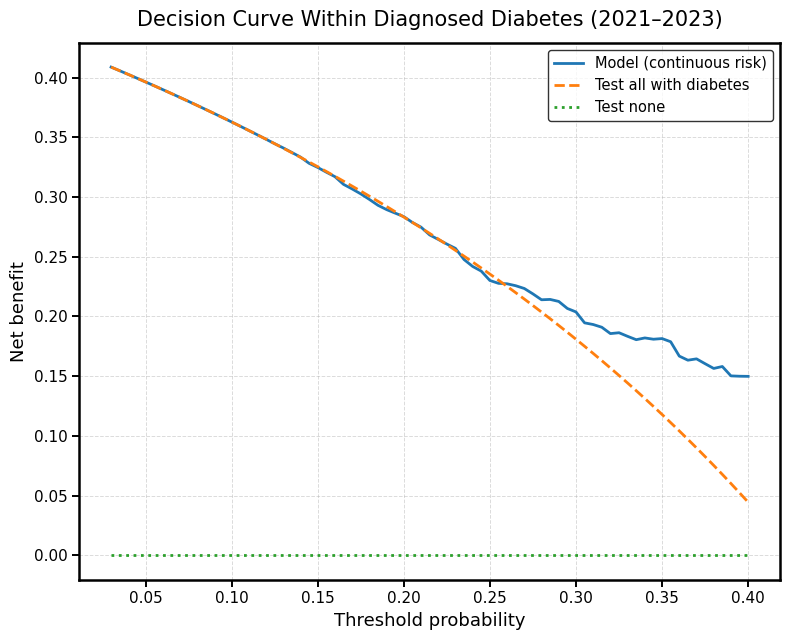

Within diagnosed diabetes, model net benefit first exceeds 'test all' at threshold probability: 0.130

Completed in 17.3 seconds.


17.317964792251587

In [ ]:
banner("REVISION G: Subgroup CIs and screening policies (R2.8, R2.9, R3m5, R4.2)")
t0 = time.time()

runner.run_subgroup_uncertainty_and_policies()

finish_block(t0)

In [ ]:
banner("REVISION H: Age dependence and outcome components (R2.11, R3m2, R4.3)")
t0 = time.time()

runner.run_age_dependence()

finish_block(t0)


REVISION H: Age dependence and outcome components (R2.11, R3m2, R4.3)
[HistGradientBoosting age only] dev OOF AUC=0.7378 | temporal AUC=0.7362 | frozen threshold=0.1359


,cohort,outcome,n_positive,prevalence,auc_primary,auc_age_only,auc_age_removed,auc_increment_over_age_only,pr_auc_primary,sensitivity_at_frozen_threshold,sensitivity_wilson_low,sensitivity_wilson_high,primary_ci_low,primary_ci_high,age_only_ci_low,age_only_ci_high,age_removed_ci_low,age_removed_ci_high,increment_ci_low,increment_ci_high
0,2017-2018 development OOF,CKD screening phenotype,939,0.1855,0.7864,0.7378,0.7576,0.0486,0.4833,0.8009,0.7741,0.8251,0.7695,0.8025,0.7194,0.7554,0.7404,0.7750,0.0375,0.0596
1,2017-2018 development OOF,Reduced eGFR (<60),411,0.0812,0.8585,0.8538,0.7964,0.0046,0.3384,0.9343,0.9061,0.9545,0.8429,0.8741,0.8362,0.8707,0.7748,0.8176,-0.0077,0.0165
2,2017-2018 development OOF,Albuminuria (ACR >=30),686,0.1355,0.7377,0.6657,0.7348,0.0720,0.3357,0.7595,0.7261,0.7900,0.7176,0.7581,0.6440,0.6876,0.7146,0.7550,0.0585,0.0859
3,2021-2023 temporal,CKD screening phenotype,949,0.1709,0.7949,0.7362,0.7515,0.0587,0.4830,0.8251,0.7996,0.8479,0.7788,0.8115,0.7189,0.7536,0.7337,0.7691,0.0464,0.0707
4,2021-2023 temporal,Reduced eGFR (<60),454,0.0818,0.8501,0.8394,0.7540,0.0107,0.3202,0.9251,0.8972,0.9459,0.8336,0.8660,0.8230,0.8553,0.7312,0.7761,-0.0019,0.0238
5,2021-2023 temporal,Albuminuria (ACR >=30),638,0.1149,0.7441,0.6521,0.7446,0.0919,0.3138,0.7868,0.7534,0.8168,0.7228,0.7654,0.6306,0.6743,0.7214,0.7667,0.0766,0.1078


,outcome,age_group,n,cases,status,auc_primary,auc_primary_ci_low,auc_primary_ci_high,auc_age_only,auc_age_only_ci_low,auc_age_only_ci_high
0,CKD screening phenotype,18-39,1562,88,evaluated,0.6302,0.5638,0.6968,0.5268,0.4660,0.5886
1,CKD screening phenotype,40-59,1557,183,evaluated,0.7175,0.6755,0.7575,0.5625,0.5235,0.6038
2,CKD screening phenotype,60+,2433,678,evaluated,0.7593,0.7403,0.7803,0.6784,0.6533,0.7008
3,Reduced eGFR (<60),18-39,1562,1,insufficient_events,NaN,NaN,NaN,NaN,NaN,NaN
4,Reduced eGFR (<60),40-59,1557,53,evaluated,0.7014,0.6308,0.7727,0.5919,0.5364,0.6512
5,Reduced eGFR (<60),60+,2433,400,evaluated,0.7485,0.7250,0.7726,0.7211,0.6955,0.7463
6,Albuminuria (ACR >=30),18-39,1562,87,evaluated,0.6312,0.5641,0.6995,0.5226,0.4615,0.5840
7,Albuminuria (ACR >=30),40-59,1557,152,evaluated,0.7302,0.6836,0.7725,0.5618,0.5164,0.6082
8,Albuminuria (ACR >=30),60+,2433,399,evaluated,0.7326,0.7056,0.7589,0.5979,0.5664,0.6277



Completed in 154.4 seconds.


154.35524344444275

In [ ]:
banner("REVISION I: Alcohol-intake missingness sensitivity (R2.3, R3m4, R4 minor)")
t0 = time.time()

runner.run_alcohol_missingness()

finish_block(t0)


REVISION I: Alcohol-intake missingness sensitivity (R2.3, R3m4, R4 minor)


,cohort,group,n,pct_alcohol_missing,phenotype_prevalence_pct
0,2017-2018 development,overall,5063,35.55,NaN
1,2021-2023 temporal,overall,5552,34.55,NaN
2,2017-2018 development,phenotype positive,939,49.20,NaN
3,2017-2018 development,phenotype negative,4124,32.44,NaN
4,2017-2018 development,age 18-39,1694,26.27,NaN
5,2017-2018 development,age 40-59,1542,31.97,NaN
6,2017-2018 development,age 60+,1827,47.18,NaN
7,2017-2018 development,phenotype prevalence | alcohol missing,1800,NaN,25.67
8,2017-2018 development,phenotype prevalence | alcohol observed,3263,NaN,14.62
9,2017-2018 development,missing ALQ130 explained by skip pattern (non-...,1800,28.28,NaN


[V1 alcohol removed (11 predictors)] dev OOF AUC=0.7827 | temporal AUC=0.7933 | frozen threshold=0.1237
[V2 median imputation + missingness indicator] dev OOF AUC=0.7866 | temporal AUC=0.7929 | frozen threshold=0.1326
Remaining ALQ130 missingness after skip-pattern recode: dev 25.5%, temporal 26.1%
[V3 skip-pattern recode (non-drinkers = 0)] dev OOF AUC=0.7870 | temporal AUC=0.7947 | frozen threshold=0.1249


,model,frozen_threshold,dev_roc_auc,dev_brier,temporal_roc_auc,temporal_pr_auc,temporal_brier,temporal_cal_intercept,temporal_cal_slope,temporal_ece,temporal_sensitivity,temporal_specificity,temporal_weighted_sensitivity,temporal_weighted_specificity,temporal_auc_minus_V0,temporal_auc_minus_V0_ci_low,temporal_auc_minus_V0_ci_high,temporal_brier_minus_V0,temporal_brier_minus_V0_ci_low,temporal_brier_minus_V0_ci_high
0,"HistGradientBoosting (primary, 12 predictors)",0.1239,0.7864,0.1224,0.7949,0.4830,0.1142,0.0970,1.1406,0.0169,0.8251,0.6037,0.7671,0.7014,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,V1 alcohol removed (11 predictors),0.1237,0.7827,0.1229,0.7933,0.4843,0.1145,0.0604,1.1374,0.0189,0.8282,0.6000,0.7669,0.7024,-0.0017,-0.0040,0.0008,0.0003,-0.0002,0.0007
2,V2 median imputation + missingness indicator,0.1326,0.7866,0.1227,0.7929,0.4840,0.1142,0.1386,1.1621,0.0192,0.8135,0.6233,0.7484,0.7225,-0.0020,-0.0051,0.0011,0.0001,-0.0005,0.0006
3,V3 skip-pattern recode (non-drinkers = 0),0.1249,0.7870,0.1224,0.7947,0.4814,0.1142,0.1068,1.1413,0.0159,0.8240,0.6118,0.7653,0.7101,-0.0003,-0.0013,0.0007,-0.0000,-0.0002,0.0002



Completed in 128.3 seconds.


128.2730529308319


REVISION J: Screening scenarios and DCA threshold interpretation (R2.10, R3.5)


,threshold_probability,false_positive_tests_accepted_per_case_found,max_total_tests_per_case_found,is_frozen_threshold
0,0.03,32.33,33.33,False
1,0.05,19.00,20.00,False
2,0.08,11.50,12.50,False
3,0.10,9.00,10.00,False
4,0.12,7.07,8.07,True
5,0.15,5.67,6.67,False
6,0.20,4.00,5.00,False
7,0.30,2.33,3.33,False
8,0.40,1.50,2.50,False


,strategy,scale,referred_for_confirmatory_testing_per_10000,screening_positive_cases_found_per_10000,screening_positive_cases_missed_per_10000,unnecessary_referrals_per_10000,tests_per_case_found,share_of_cases_found
0,"Model, threshold 0.050",NHANES sample,9146.3,1673.3,36.0,7473.0,5.5,1.0
1,"Model, threshold 0.080",NHANES sample,5925.8,1507.6,201.7,4418.2,3.9,0.9
2,"Model, threshold 0.095 [survey-weighted thresh...",NHANES sample,5354.8,1467.9,241.4,3886.9,3.6,0.9
3,"Model, threshold 0.100",NHANES sample,5217.9,1448.1,261.2,3769.8,3.6,0.8
4,"Model, threshold 0.124 [frozen primary threshold]",NHANES sample,4695.6,1410.3,299.0,3285.3,3.3,0.8
5,"Model, threshold 0.150",NHANES sample,4117.4,1350.9,358.4,2766.6,3.0,0.8
6,"Model, threshold 0.200",NHANES sample,3305.1,1228.4,480.9,2076.7,2.7,0.7
7,"Model, threshold 0.250",NHANES sample,2698.1,1100.5,608.8,1597.6,2.5,0.6
8,"Model, threshold 0.300",NHANES sample,2175.8,972.6,736.7,1203.2,2.2,0.6
9,Rule: diabetes or hypertension,NHANES sample,3996.8,1192.4,516.9,2804.4,3.4,0.7


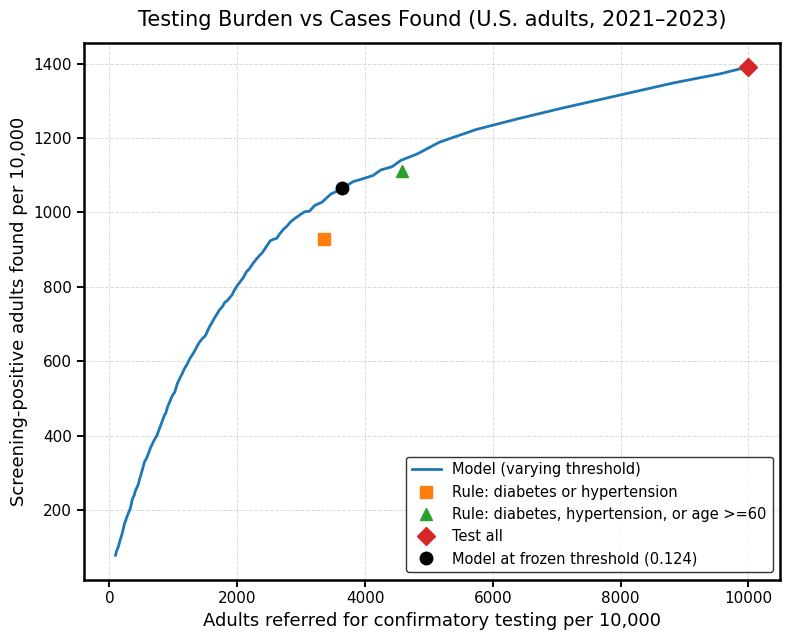


Completed in 3.1 seconds.


3.147961378097534

In [ ]:
banner("REVISION J: Screening scenarios and DCA threshold interpretation (R2.10, R3.5)")
t0 = time.time()

runner.run_screening_scenarios()

finish_block(t0)

In [ ]:
banner("REVISION K: Correlation-aware permutation importance (R3m3)")
t0 = time.time()

runner.run_correlated_importance()

finish_block(t0)


REVISION K: Correlation-aware permutation importance (R3m3)


,Age,Sex,Education,Income-to-poverty ratio,Diagnosed hypertension,Diagnosed diabetes,BMI,Waist circumference,Smoking history,Alcohol intake,Mean systolic BP,Mean diastolic BP
Age,1.00,-0.03,-0.07,0.09,0.44,0.32,0.06,0.22,0.16,-0.26,0.51,0.03
Sex,-0.03,1.00,0.04,-0.03,-0.02,-0.07,0.03,-0.12,-0.21,-0.21,-0.09,-0.13
Education,-0.07,0.04,1.00,0.45,-0.03,-0.09,-0.05,-0.07,-0.14,-0.18,-0.10,0.05
Income-to-poverty ratio,0.09,-0.03,0.45,1.00,0.02,-0.01,-0.03,-0.03,-0.12,-0.14,0.00,0.04
Diagnosed hypertension,0.44,-0.02,-0.03,0.02,1.00,0.30,0.21,0.29,0.12,-0.06,0.40,0.12
Diagnosed diabetes,0.32,-0.07,-0.09,-0.01,0.30,1.00,0.16,0.23,0.09,-0.06,0.17,-0.05
BMI,0.06,0.03,-0.05,-0.03,0.21,0.16,1.00,0.91,0.04,0.03,0.18,0.12
Waist circumference,0.22,-0.12,-0.07,-0.03,0.29,0.23,0.91,1.00,0.14,0.03,0.27,0.15
Smoking history,0.16,-0.21,-0.14,-0.12,0.12,0.09,0.04,0.14,1.00,0.19,0.08,0.01
Alcohol intake,-0.26,-0.21,-0.18,-0.14,-0.06,-0.06,0.03,0.03,0.19,1.00,-0.04,0.05


,predictor_1,predictor_2,spearman_rho,abs_rho
51,BMI,Waist circumference,0.910,0.910
9,Age,Mean systolic BP,0.511,0.511
21,Education,Income-to-poverty ratio,0.451,0.451
65,Mean systolic BP,Mean diastolic BP,0.447,0.447
3,Age,Diagnosed hypertension,0.444,0.444
43,Diagnosed hypertension,Mean systolic BP,0.401,0.401
4,Age,Diagnosed diabetes,0.318,0.318
38,Diagnosed hypertension,Diagnosed diabetes,0.296,0.296
40,Diagnosed hypertension,Waist circumference,0.287,0.287
58,Waist circumference,Mean systolic BP,0.265,0.265


,group,predictors,n_predictors,grouped_auc_drop_mean,grouped_auc_drop_sd,sum_of_individual_drops,grouped_minus_sum_of_individual
9,All non-age predictors,"Sex, Education, Income-to-poverty ratio, Diagn...",11,0.1196,0.0055,0.0654,0.0542
0,Age,Age,1,0.1145,0.0065,0.1151,-0.0006
6,Cardiometabolic (diabetes + hypertension + BP ...,"Diagnosed diabetes, Diagnosed hypertension, Me...",6,0.1032,0.0051,0.0608,0.0424
3,Hypertension diagnosis + BP,"Diagnosed hypertension, Mean systolic BP, Mean...",3,0.0387,0.0040,0.0270,0.0117
5,Diagnosed diabetes,Diagnosed diabetes,1,0.0318,0.0033,0.0307,0.0012
2,Blood pressure (SBP + DBP),"Mean systolic BP, Mean diastolic BP",2,0.0137,0.0015,0.0112,0.0025
7,Socioeconomic (education + income-to-poverty),"Education, Income-to-poverty ratio",2,0.0056,0.0015,0.0047,0.0008
4,Adiposity (BMI + waist),"BMI, Waist circumference",2,0.0036,0.0010,0.0031,0.0005
1,Sex,Sex,1,0.0004,0.0002,0.0004,0.0000
8,Lifestyle (smoking + alcohol),"Smoking history, Alcohol intake",2,-0.0007,0.0007,-0.0005,-0.0002


A grouped drop larger than the sum of individual drops indicates shared (redundant) information that single-feature permutation hides.

Completed in 64.4 seconds.


64.39012956619263

In [ ]:
banner("REVISION L: Blood-pressure protocol sensitivity, BPXO_J (R4 minor)")
t0 = time.time()

runner.run_blood_pressure_protocol()

finish_block(t0)


REVISION L: Blood-pressure protocol sensitivity, BPXO_J (R4 minor)
Development participants with oscillometric SBP: 4495 of 5063
Development participants with auscultatory SBP: 4839 of 5063


,measure,n_paired,mean_auscultatory,mean_oscillometric,mean_difference_osc_minus_ausc,sd_difference,lower_limit_of_agreement,upper_limit_of_agreement,pearson_r
0,Systolic BP,4386,126.09,124.56,-1.53,10.20,-21.53,18.47,0.86
1,Diastolic BP,4386,72.33,74.34,2.01,9.19,-16.00,20.02,0.72


,mean_prediction_change,mean_absolute_prediction_change,p95_absolute_prediction_change,pct_reclassified_at_frozen_threshold,note
0,-0.0035,0.0133,0.0649,1.9751,Frozen model applied to development participan...


[HistGradientBoosting with oscillometric BP in development] dev OOF AUC=0.7856 | temporal AUC=0.7933 | frozen threshold=0.1288


,model,frozen_threshold,dev_roc_auc,dev_brier,temporal_roc_auc,temporal_pr_auc,temporal_brier,temporal_cal_intercept,temporal_cal_slope,temporal_ece,temporal_sensitivity,temporal_specificity,temporal_weighted_sensitivity,temporal_weighted_specificity,development_bp_protocol,temporal_auc_minus_primary,temporal_auc_minus_primary_ci_low,temporal_auc_minus_primary_ci_high
0,"HistGradientBoosting (primary, 12 predictors)",0.1239,0.7864,0.1224,0.7949,0.4830,0.1142,0.097,1.1406,0.0169,0.8251,0.6037,0.7671,0.7014,auscultatory (BPX_J),0.0000,NaN,NaN
1,HistGradientBoosting with oscillometric BP in ...,0.1288,0.7856,0.1234,0.7933,0.4758,0.1147,0.028,1.1166,0.0186,0.8177,0.6040,0.7528,0.7008,oscillometric (BPXO_J),-0.0017,-0.0042,0.0008



Completed in 35.5 seconds.


35.53021955490112

## 6. Final outputs

In [ ]:
banner("REVISION SUMMARY: Comment map, key numbers, reproducibility record")
t0 = time.time()

runner.finalize_revision_outputs()

comment_map = runner.get("comment_output_map")
if comment_map is not None:
    display(comment_map)

finish_block(t0)


REVISION SUMMARY: Comment map, key numbers, reproducibility record


,reviewer,comment,module,output_files,analysis
0,Reviewer 1,Main (novelty),"29, 30, 28",R1c1_R4c1_*; R1c3_*; R3c1_R4c5_selection_under...,Comparators/rules under identical procedure; t...
1,Reviewer 1,1,29,R1c1_R4c1_comparator_and_ablation_models.csv; ...,"Simpler models, risk-factor rules, 12-predicto..."
2,Reviewer 1,2,28 (Part E),R1c2_fully_nested_procedure_folds.csv; R1c2_fu...,Tuning -> calibration -> threshold sequence; f...
3,Reviewer 1,3,30,R1c3_weighted_vs_unweighted_threshold.csv; R1c...,"Survey-weighted 80% threshold, frozen and tran..."
4,Reviewer 2,1,—,manuscript text (Abstract),State single-visit CKD-compatible phenotype in...
5,Reviewer 2,2,27,R2c2_included_vs_excluded.csv,Included vs excluded (missing creatinine/ACR)
6,Reviewer 2,3,35,R2c3_alcohol_sensitivity_models.csv; R2c3_alco...,Alcohol removed / indicator / skip-pattern recode
7,Reviewer 2,4,28 (Part A),R2c4_one_se_rule_details.csv; R2c4_best_model_...,One-SE rule rationale and SE computation
8,Reviewer 2,5,28 (Part C),R2c5_calibration_method_paired_differences.csv,Sigmoid vs isotonic differences with CIs
9,Reviewer 2,6,27,R2c6_prevalence_n_over_N.csv,"Prevalence n/N and %, both cohorts"


{
  "primary_frozen_threshold": 0.12389798647763042,
  "survey_weighted_threshold": 0.09482950186510727,
  "temporal_auc_primary": 0.7949216241663989
}

Revision outputs saved to: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/revision_round1
Files: 51


,reviewer,comment,module,output_files,analysis
0,Reviewer 1,Main (novelty),"29, 30, 28",R1c1_R4c1_*; R1c3_*; R3c1_R4c5_selection_under...,Comparators/rules under identical procedure; t...
1,Reviewer 1,1,29,R1c1_R4c1_comparator_and_ablation_models.csv; ...,"Simpler models, risk-factor rules, 12-predicto..."
2,Reviewer 1,2,28 (Part E),R1c2_fully_nested_procedure_folds.csv; R1c2_fu...,Tuning -> calibration -> threshold sequence; f...
3,Reviewer 1,3,30,R1c3_weighted_vs_unweighted_threshold.csv; R1c...,"Survey-weighted 80% threshold, frozen and tran..."
4,Reviewer 2,1,—,manuscript text (Abstract),State single-visit CKD-compatible phenotype in...
5,Reviewer 2,2,27,R2c2_included_vs_excluded.csv,Included vs excluded (missing creatinine/ACR)
6,Reviewer 2,3,35,R2c3_alcohol_sensitivity_models.csv; R2c3_alco...,Alcohol removed / indicator / skip-pattern recode
7,Reviewer 2,4,28 (Part A),R2c4_one_se_rule_details.csv; R2c4_best_model_...,One-SE rule rationale and SE computation
8,Reviewer 2,5,28 (Part C),R2c5_calibration_method_paired_differences.csv,Sigmoid vs isotonic differences with CIs
9,Reviewer 2,6,27,R2c6_prevalence_n_over_N.csv,"Prevalence n/N and %, both cohorts"



Completed in 0.9 seconds.


0.9259614944458008

## 7. Figures

Module 40 saves the numbers behind each figure to `mlwa_results/figure_data/`; module 41 draws the six manuscript figures and Supplementary Figure S1 into `mlwa_results/figures/` (EPS, PDF, PNG). To restyle a figure later without re-running the pipeline, edit `make_figures.py` in the project folder and run `%run make_figures.py 1` (or any figure number).


In [ ]:
banner("FIGURES A: Save the data behind every figure")
t0 = time.time()

runner.export_figure_data()

finish_block(t0)


FIGURES A: Save the data behind every figure
Figure data written to: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figure_data
   fig1_internal_calibration_points.csv
   fig2_calibration_transport_points.csv
   fig3_fig5_threshold_tradeoff.csv
   fig4_decision_curves.csv
   fig5_model_curve.csv
   fig5_screening_scenarios.csv
   fig6_permutation_importance.csv
   figS1_dca_within_diabetes.csv
   figure_constants.json

Completed in 1.0 seconds.


0.9623210430145264


FIGURES B: Draw Figures 1-6 and Supplementary Figure S1


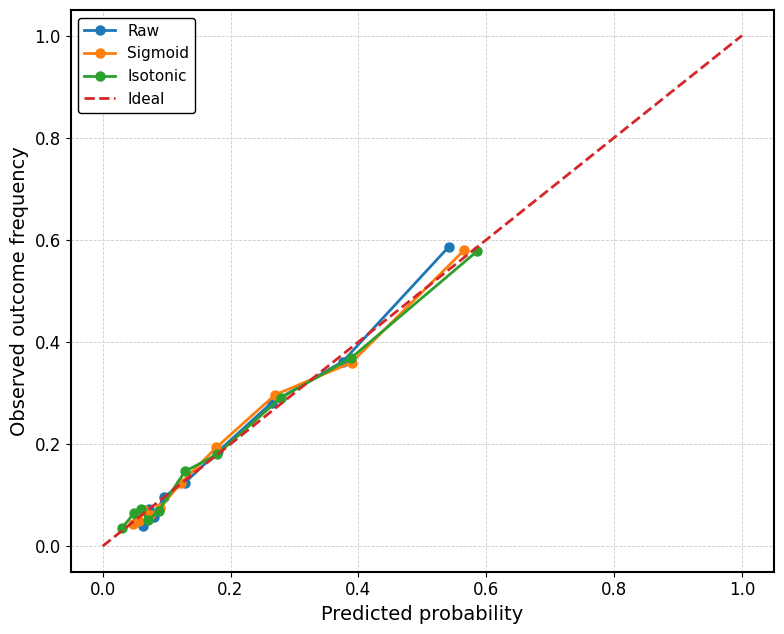

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/internal_calibration_oof.[png|pdf|eps]


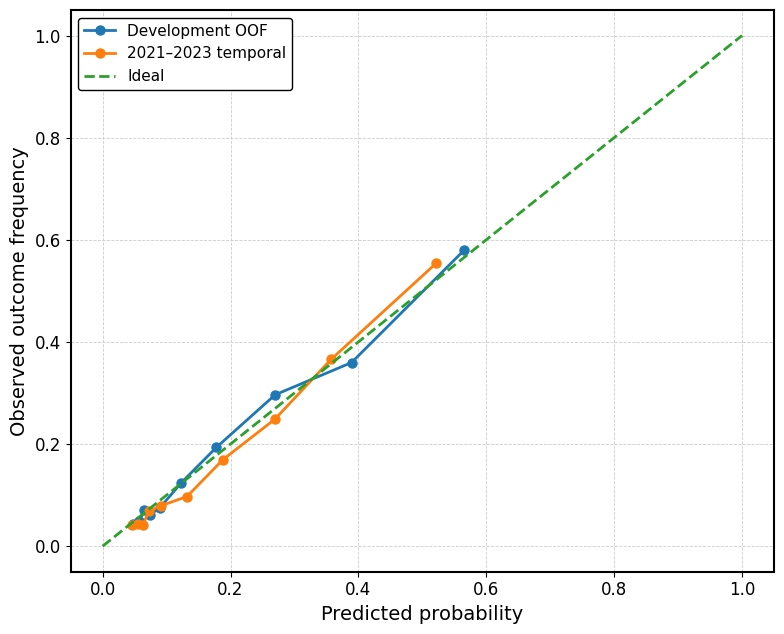

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/calibration_transport.[png|pdf|eps]


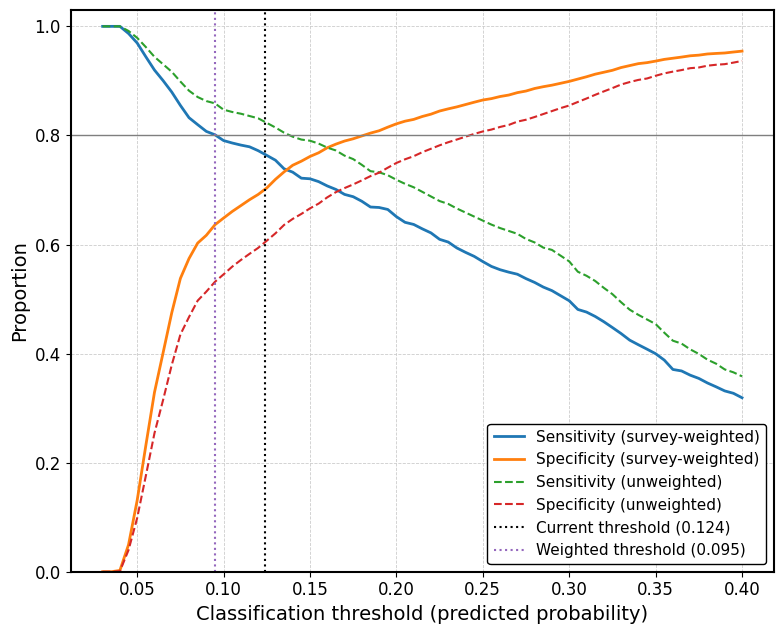

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/threshold_tradeoff_weighted_temporal.[png|pdf|eps]


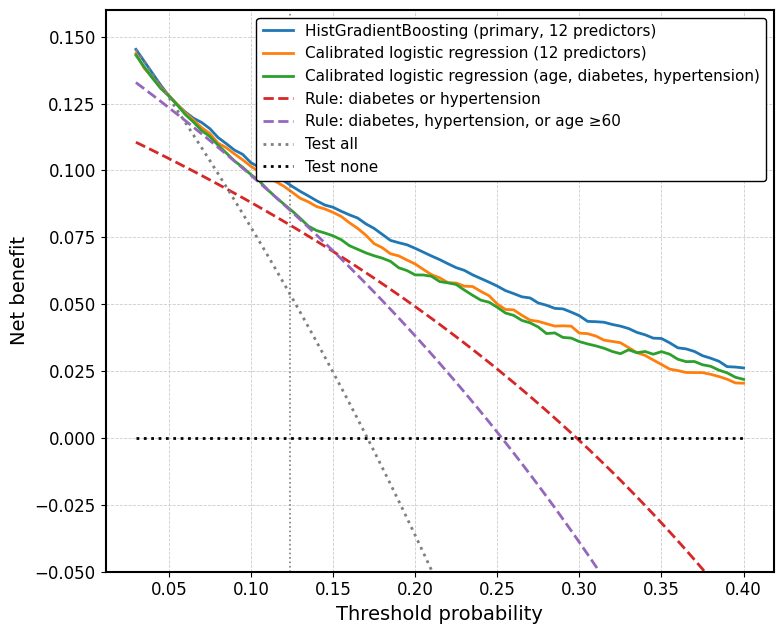

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/decision_curve_models_vs_rules_temporal.[png|pdf|eps]


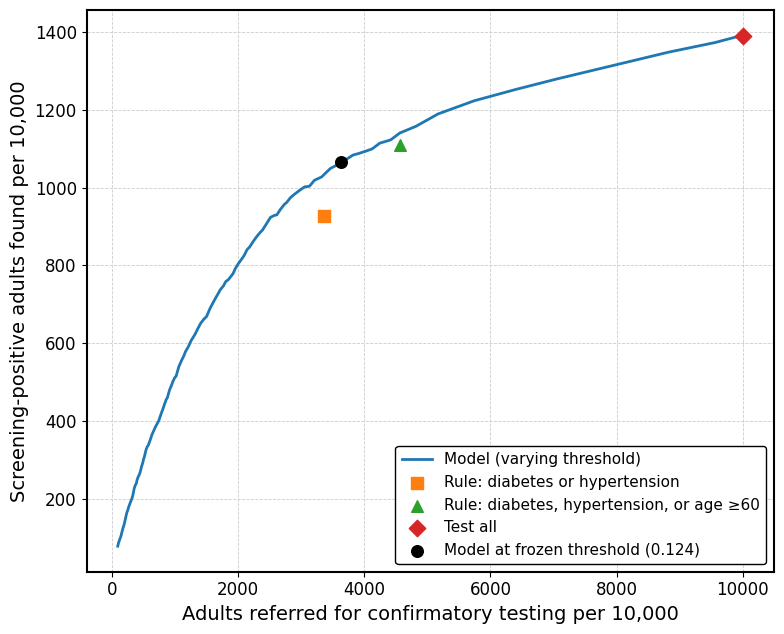

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/testing_burden_vs_cases_found_temporal.[png|pdf|eps]


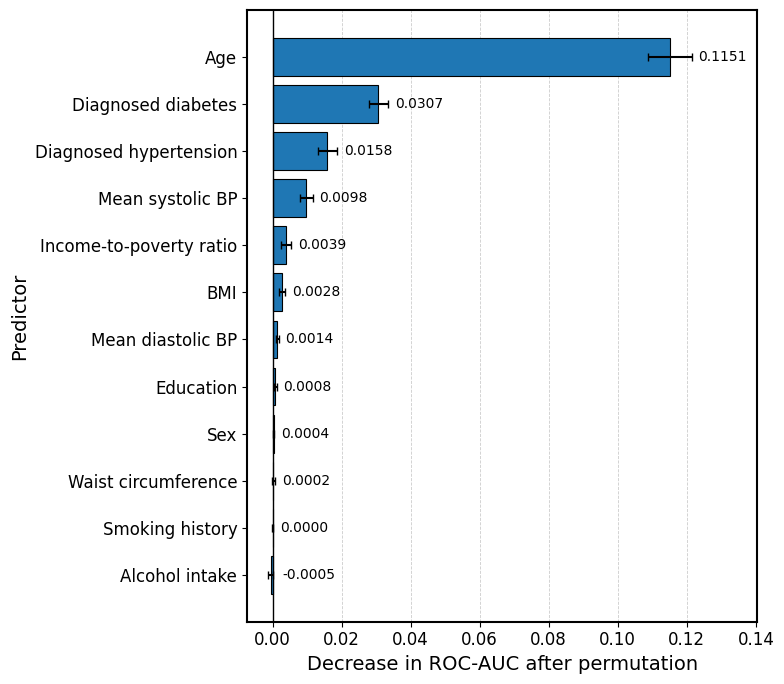

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/temporal_permutation_importance.[png|pdf|eps]


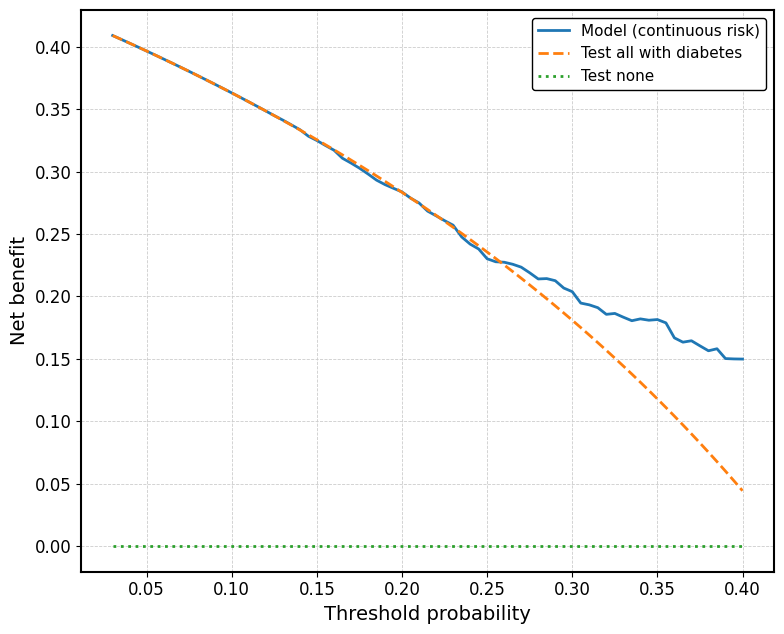

saved  /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures/decision_curve_within_diabetes_temporal.[png|pdf|eps]
Figures written to: /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures

Completed in 20.5 seconds.


20.50264286994934

In [ ]:
banner("FIGURES B: Draw Figures 1-6 and Supplementary Figure S1")
t0 = time.time()

runner.make_figures()

finish_block(t0)

In [ ]:
banner("CKD PIPELINE COMPLETE (PRIMARY ANALYSIS + REVISION 1)")

print("Project root      :", PROJECT_ROOT)
print("Primary results   :", runner.get("RESULTS_DIR"))
print("Revision results  :", runner.get("REVISION_DIR"))
print("Figures           :", runner.get("RESULTS_DIR") / "figures")
print(f"Total run time    : {(time.time() - PIPELINE_T0) / 60:.1f} minutes")


CKD PIPELINE COMPLETE (PRIMARY ANALYSIS + REVISION 1)
Project root      : /content/drive/MyDrive/CKD-Paper-Final/ckd-project
Primary results   : /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results
Revision results  : /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/revision_round1
Figures           : /content/drive/MyDrive/CKD-Paper-Final/ckd-project/mlwa_results/figures
Total run time    : 37.3 minutes
